In [ ]:
# Install required library
!pip install yfinance --quiet

# Import libraries
import yfinance as yf
import pandas as pd
import numpy as np
import os
from datetime import datetime

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Our 3 stocks with updated tickers
stocks = {
    "TVS Motor"        : "TVSMOTOR.NS",
    "Solar Industries" : "SOLARINDS.NS",
    "HDFC Bank"        : "HDFCBANK.NS"
}

# Date range — 6+ years of data
start_date = "2019-01-01"
end_date   = datetime.today().strftime("%Y-%m-%d")

print(f"Stocks selected  : {list(stocks.keys())}")
print(f"Fetching data from {start_date} to {end_date}")

Stocks selected  : ['TVS Motor', 'Solar Industries', 'HDFC Bank']
Fetching data from 2019-01-01 to 2026-08-19


In [ ]:
# Dictionary to store all stock dataframes
stock_data = {}

for name, ticker in stocks.items():
    print(f"Downloading {name} ({ticker})...")

    df = yf.download(ticker, start=start_date, end=end_date, auto_adjust=True)

    # Add stock name column
    df["Stock"] = name

    stock_data[name] = df
    print(f"  {name}: {len(df)} rows downloaded")

print("\nAll stocks downloaded successfully!")

[*********************100%***********************]  1 of 1 completed


  TVS Motor: 1888 rows downloaded


[*********************100%***********************]  1 of 1 completed


  Solar Industries: 1887 rows downloaded


[*********************100%***********************]  1 of 1 completed

  HDFC Bank: 1888 rows downloaded

All stocks downloaded successfully!


In [ ]:
# Preview TVS Motor data
print("=== TVS MOTOR SAMPLE DATA ===")
print(stock_data["TVS Motor"].head(10))

print("\n=== COLUMN NAMES ===")
print(stock_data["TVS Motor"].columns.tolist())

=== TVS MOTOR SAMPLE DATA ===
Price            Close        High         Low        Open      Volume  \
Ticker     TVSMOTOR.NS TVSMOTOR.NS TVSMOTOR.NS TVSMOTOR.NS TVSMOTOR.NS   
Date                                                                     
2019-01-01  542.667786  551.511201  539.447657  547.906553      525625   
2019-01-02  514.503418  553.337515  510.418150  542.523572     3650090   
2019-01-03  517.002686  523.491053  512.100387  514.263176     1447966   
2019-01-04  519.982483  524.740630  514.887926  516.185575      857655   
2019-01-07  514.022827  524.548411  512.677068  522.625932      629458   
2019-01-08  514.407349  519.405747  503.737555  514.022829     1321223   
2019-01-09  518.732971  523.346910  511.860085  515.128323     1068861   
2019-01-10  519.213623  524.644592  516.906624  519.069414      653168   
2019-01-11  519.694092  523.298739  514.599476  519.213472      599137   
2019-01-14  514.215088  519.549955  510.898800  518.684816      587034   

Price  

In [ ]:
for name, df in stock_data.items():
    print(f"\n=== {name} ===")
    print(f"  Total rows     : {len(df)}")
    print(f"  Date range     : {df.index[0].date()} to {df.index[-1].date()}")
    print(f"  Missing values : {df.isnull().sum().sum()}")
    print(f"  Columns        : {df.columns.tolist()}")



=== TVS Motor ===
  Total rows     : 1888
  Date range     : 2019-01-01 to 2026-08-18
  Missing values : 0
  Columns        : [('Close', 'TVSMOTOR.NS'), ('High', 'TVSMOTOR.NS'), ('Low', 'TVSMOTOR.NS'), ('Open', 'TVSMOTOR.NS'), ('Volume', 'TVSMOTOR.NS'), ('Stock', '')]

=== Solar Industries ===
  Total rows     : 1887
  Date range     : 2019-01-01 to 2026-08-18
  Missing values : 4
  Columns        : [('Close', 'SOLARINDS.NS'), ('High', 'SOLARINDS.NS'), ('Low', 'SOLARINDS.NS'), ('Open', 'SOLARINDS.NS'), ('Volume', 'SOLARINDS.NS'), ('Stock', '')]

=== HDFC Bank ===
  Total rows     : 1888
  Date range     : 2019-01-01 to 2026-08-18
  Missing values : 0
  Columns        : [('Close', 'HDFCBANK.NS'), ('High', 'HDFCBANK.NS'), ('Low', 'HDFCBANK.NS'), ('Open', 'HDFCBANK.NS'), ('Volume', 'HDFCBANK.NS'), ('Stock', '')]


In [ ]:
# Create folder
os.makedirs("stock_data", exist_ok=True)

for name, df in stock_data.items():
    filename = f"stock_data/{name.replace(' ', '_')}_data.csv"
    df.to_csv(filename)
    print(f"Saved: {filename}")

print("\nAll raw files saved!")

Saved: stock_data/TVS_Motor_data.csv
Saved: stock_data/Solar_Industries_data.csv
Saved: stock_data/HDFC_Bank_data.csv

All raw files saved!


In [ ]:
# Combine all 3 into one master file
master_df = pd.concat(stock_data.values())
master_df.to_csv("stock_data/ALL_STOCKS_master.csv")

print(f"Master file saved!")
print(f"Total rows: {len(master_df)}")
print(f"\nRows per stock:")
print(master_df["Stock"].value_counts())

Master file saved!
Total rows: 5663

Rows per stock:
Stock
TVS Motor           1888
HDFC Bank           1888
Solar Industries    1887
Name: count, dtype: int64


In [ ]:
import pandas as pd
import numpy as np
import os

def load_stock_csv(filepath, stock_name):
    # Read CSV
    df = pd.read_csv(filepath, index_col=0, parse_dates=True)

    # Drop extra header rows yfinance adds
    df = df[~df.index.astype(str).str.contains(
        "Ticker|Price|Date", na=False)]

    # Convert price columns to numeric
    for col in ["Open", "High", "Low", "Close", "Volume"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # Fix date index
    df.index = pd.to_datetime(df.index, errors="coerce")

    # Drop rows where index is not a valid date
    df = df[df.index.notna()]

    # Drop rows where Close is missing
    df = df.dropna(subset=["Close"])

    # Add stock name
    df["Stock"] = stock_name

    return df

# Load all three stocks
tvs   = load_stock_csv("stock_data/TVS_Motor_data.csv",        "TVS Motor")
solar = load_stock_csv("stock_data/Solar_Industries_data.csv", "Solar Industries")
hdfc  = load_stock_csv("stock_data/HDFC_Bank_data.csv",        "HDFC Bank")

print("All files loaded successfully!")
print(f"TVS Motor         : {tvs.shape}")
print(f"Solar Industries  : {solar.shape}")
print(f"HDFC Bank         : {hdfc.shape}")

# Verify Close column is numeric
print(f"\nTVS Close dtype    : {tvs['Close'].dtype}")
print(f"Solar Close dtype  : {solar['Close'].dtype}")
print(f"HDFC Close dtype   : {hdfc['Close'].dtype}")

/tmp/ipykernel_3405/3566943741.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv(filepath, index_col=0, parse_dates=True)
/tmp/ipykernel_3405/3566943741.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv(filepath, index_col=0, parse_dates=True)


All files loaded successfully!
TVS Motor         : (1888, 6)
Solar Industries  : (1886, 6)
HDFC Bank         : (1888, 6)

TVS Close dtype    : float64
Solar Close dtype  : float64
HDFC Close dtype   : float64


/tmp/ipykernel_3405/3566943741.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv(filepath, index_col=0, parse_dates=True)


In [ ]:
print("=== TVS MOTOR DATA TYPES ===")
print(tvs.dtypes)
print("\n=== SAMPLE DATA ===")
print(tvs.head())

=== TVS MOTOR DATA TYPES ===
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
Stock      object
dtype: object

=== SAMPLE DATA ===
                 Close        High         Low        Open   Volume      Stock
Price                                                                         
2019-01-01  542.667786  551.511201  539.447657  547.906553   525625  TVS Motor
2019-01-02  514.503418  553.337515  510.418150  542.523572  3650090  TVS Motor
2019-01-03  517.002686  523.491053  512.100387  514.263176  1447966  TVS Motor
2019-01-04  519.982483  524.740630  514.887926  516.185575   857655  TVS Motor
2019-01-07  514.022827  524.548411  512.677068  522.625932   629458  TVS Motor


In [ ]:
# We only need these columns for our analysis
columns_needed = ["Open", "High", "Low", "Close", "Volume", "Stock"]

tvs   = tvs[columns_needed]
solar = solar[columns_needed]
hdfc  = hdfc[columns_needed]

print("Columns after cleaning:")
print(tvs.columns.tolist())

Columns after cleaning:
['Open', 'High', 'Low', 'Close', 'Volume', 'Stock']


In [ ]:
# Check missing values before fix
for name, df in [("TVS Motor", tvs),
                 ("Solar Industries", solar),
                 ("HDFC Bank", hdfc)]:
    print(f"{name} missing values: {df.isnull().sum().sum()}")

# Forward fill any missing values
tvs   = tvs.ffill()
solar = solar.ffill()
hdfc  = hdfc.ffill()

# Drop any remaining nulls at the start
tvs   = tvs.dropna()
solar = solar.dropna()
hdfc  = hdfc.dropna()

print("\nMissing values after fix:")
for name, df in [("TVS Motor", tvs),
                 ("Solar Industries", solar),
                 ("HDFC Bank", hdfc)]:
    print(f"  {name}: {df.isnull().sum().sum()}")

TVS Motor missing values: 0
Solar Industries missing values: 0
HDFC Bank missing values: 0

Missing values after fix:
  TVS Motor: 0
  Solar Industries: 0
  HDFC Bank: 0


In [ ]:
# Daily return = % change in price from previous day
tvs["Daily_Return"]   = tvs["Close"].pct_change() * 100
solar["Daily_Return"] = solar["Close"].pct_change() * 100
hdfc["Daily_Return"]  = hdfc["Close"].pct_change() * 100

# Cumulative return = total % gain since start date
tvs["Cumulative_Return"]   = (1 + tvs["Daily_Return"] / 100).cumprod() - 1
solar["Cumulative_Return"] = (1 + solar["Daily_Return"] / 100).cumprod() - 1
hdfc["Cumulative_Return"]  = (1 + hdfc["Daily_Return"] / 100).cumprod() - 1

print("Daily Return and Cumulative Return columns added!")
print("\nSample TVS Motor daily returns:")
print(tvs["Daily_Return"].dropna().head(5))

Daily Return and Cumulative Return columns added!

Sample TVS Motor daily returns:
Price
2019-01-02   -5.189983
2019-01-03    0.485763
2019-01-04    0.576360
2019-01-07   -1.146126
2019-01-08    0.074806
Name: Daily_Return, dtype: float64


In [ ]:
# Step 5 + 6 Combined Fix — CORRECT VERSION

for name, df in [("TVS Motor", tvs),
                 ("Solar Industries", solar),
                 ("HDFC Bank", hdfc)]:
    print(f"{name} columns: {df.columns.tolist()}")

# Add Daily Return
tvs["Daily_Return"]   = tvs["Close"].pct_change() * 100
solar["Daily_Return"] = solar["Close"].pct_change() * 100
hdfc["Daily_Return"]  = hdfc["Close"].pct_change() * 100

# Add Cumulative Return
tvs["Cumulative_Return"]   = (1 + tvs["Daily_Return"] / 100).cumprod() - 1
solar["Cumulative_Return"] = (1 + solar["Daily_Return"] / 100).cumprod() - 1
hdfc["Cumulative_Return"]  = (1 + hdfc["Daily_Return"] / 100).cumprod() - 1

print("\nColumns after adding returns:")
print(tvs.columns.tolist())
print("\nSample Daily Returns (TVS Motor):")
print(tvs["Daily_Return"].dropna().head(5))

TVS Motor columns: ['Open', 'High', 'Low', 'Close', 'Volume', 'Stock', 'Daily_Return', 'Cumulative_Return']
Solar Industries columns: ['Open', 'High', 'Low', 'Close', 'Volume', 'Stock', 'Daily_Return', 'Cumulative_Return']
HDFC Bank columns: ['Open', 'High', 'Low', 'Close', 'Volume', 'Stock', 'Daily_Return', 'Cumulative_Return']

Columns after adding returns:
['Open', 'High', 'Low', 'Close', 'Volume', 'Stock', 'Daily_Return', 'Cumulative_Return']

Sample Daily Returns (TVS Motor):
Price
2019-01-02   -5.189983
2019-01-03    0.485763
2019-01-04    0.576360
2019-01-07   -1.146126
2019-01-08    0.074806
Name: Daily_Return, dtype: float64


In [ ]:
tvs   = tvs.dropna()
solar = solar.dropna()
hdfc  = hdfc.dropna()

print("First NaN rows dropped!")
print(f"TVS Motor        : {len(tvs)} rows")
print(f"Solar Industries : {len(solar)} rows")
print(f"HDFC Bank        : {len(hdfc)} rows")

First NaN rows dropped!
TVS Motor        : 1887 rows
Solar Industries : 1885 rows
HDFC Bank        : 1887 rows


In [ ]:
print("=== FINAL CLEAN DATA SUMMARY ===\n")

for name, df in [("TVS Motor", tvs),
                 ("Solar Industries", solar),
                 ("HDFC Bank", hdfc)]:
    print(f"--- {name} ---")
    print(f"  Rows           : {len(df)}")
    print(f"  Columns        : {df.columns.tolist()}")
    print(f"  Date range     : {df.index[0].date()} to {df.index[-1].date()}")
    print(f"  Missing values : {df.isnull().sum().sum()}")
    print(f"  Avg Close      : Rs.{df['Close'].mean():.2f}")
    print(f"  Max Close      : Rs.{df['Close'].max():.2f}")
    print(f"  Min Close      : Rs.{df['Close'].min():.2f}")
    print()

=== FINAL CLEAN DATA SUMMARY ===

--- TVS Motor ---
  Rows           : 1887
  Columns        : ['Open', 'High', 'Low', 'Close', 'Volume', 'Stock', 'Daily_Return', 'Cumulative_Return']
  Date range     : 2019-01-02 to 2026-08-18
  Missing values : 0
  Avg Close      : Rs.1469.32
  Max Close      : Rs.4466.20
  Min Close      : Rs.245.87

--- Solar Industries ---
  Rows           : 1885
  Columns        : ['Open', 'High', 'Low', 'Close', 'Volume', 'Stock', 'Daily_Return', 'Cumulative_Return']
  Date range     : 2019-01-02 to 2026-08-17
  Missing values : 0
  Avg Close      : Rs.5751.12
  Max Close      : Rs.20324.00
  Min Close      : Rs.837.29

--- HDFC Bank ---
  Rows           : 1887
  Columns        : ['Open', 'High', 'Low', 'Close', 'Volume', 'Stock', 'Daily_Return', 'Cumulative_Return']
  Date range     : 2019-01-02 to 2026-08-18
  Missing values : 0
  Avg Close      : Rs.713.53
  Max Close      : Rs.996.42
  Min Close      : Rs.357.66



In [ ]:
os.makedirs("stock_data_clean", exist_ok=True)

tvs.to_csv("stock_data_clean/TVS_Motor_clean.csv")
solar.to_csv("stock_data_clean/Solar_Industries_clean.csv")
hdfc.to_csv("stock_data_clean/HDFC_Bank_clean.csv")

# Save master clean file
master_clean = pd.concat([tvs, solar, hdfc])
master_clean.to_csv("stock_data_clean/ALL_STOCKS_clean.csv")

print("All clean files saved!")
print(f"\nTotal rows in master : {len(master_clean)}")
print(f"\nRows per stock:")
print(master_clean["Stock"].value_counts())

All clean files saved!

Total rows in master : 5659

Rows per stock:
Stock
TVS Motor           1887
HDFC Bank           1887
Solar Industries    1885
Name: count, dtype: int64


In [ ]:
os.makedirs("stock_data_clean", exist_ok=True)

solar.to_csv("stock_data_clean/Solar_Industries_clean.csv")
tvs.to_csv("stock_data_clean/TVS_Motor_clean.csv")
hdfc.to_csv("stock_data_clean/HDFC_clean.csv")

# Save master clean file
master_clean = pd.concat([solar, tvs, hdfc])
master_clean.to_csv("stock_data_clean/ALL_STOCKS_clean.csv")

print("Clean files saved!")
print(f"Total rows in clean master: {len(master_clean)}")

Clean files saved!
Total rows in clean master: 5659


In [ ]:
# Reload master and check exact rows per stock
master = pd.read_csv("stock_data_clean/ALL_STOCKS_clean.csv",
                     index_col=0, parse_dates=True)

print(f"Total rows : {len(master)}")
print(f"\nRows per stock:")
print(master["Stock"].value_counts())

Total rows : 5659

Rows per stock:
Stock
TVS Motor           1887
HDFC Bank           1887
Solar Industries    1885
Name: count, dtype: int64


In [ ]:
# Install required libraries
!pip install plotly --quiet

# Import all visualization libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings("ignore")

# Set style for matplotlib charts
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("husl")

print("All visualization libraries imported successfully!")

All visualization libraries imported successfully!


In [ ]:
# Reload clean data from saved CSV files
tvs   = pd.read_csv("stock_data_clean/TVS_Motor_clean.csv",
                     index_col=0, parse_dates=True)
solar = pd.read_csv("stock_data_clean/Solar_Industries_clean.csv",
                     index_col=0, parse_dates=True)
hdfc  = pd.read_csv("stock_data_clean/HDFC_clean.csv",
                     index_col=0, parse_dates=True)

# Convert all price columns to numeric
for df in [tvs, solar, hdfc]:
    for col in ["Open", "High", "Low", "Close", "Volume"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Fix date index
tvs.index   = pd.to_datetime(tvs.index,   errors="coerce")
solar.index = pd.to_datetime(solar.index, errors="coerce")
hdfc.index  = pd.to_datetime(hdfc.index,  errors="coerce")

print("Clean data reloaded successfully!")
print(f"TVS Motor        : {tvs.shape}")
print(f"Solar Industries : {solar.shape}")
print(f"HDFC Bank        : {hdfc.shape}")

Clean data reloaded successfully!
TVS Motor        : (1887, 8)
Solar Industries : (1885, 8)
HDFC Bank        : (1887, 8)


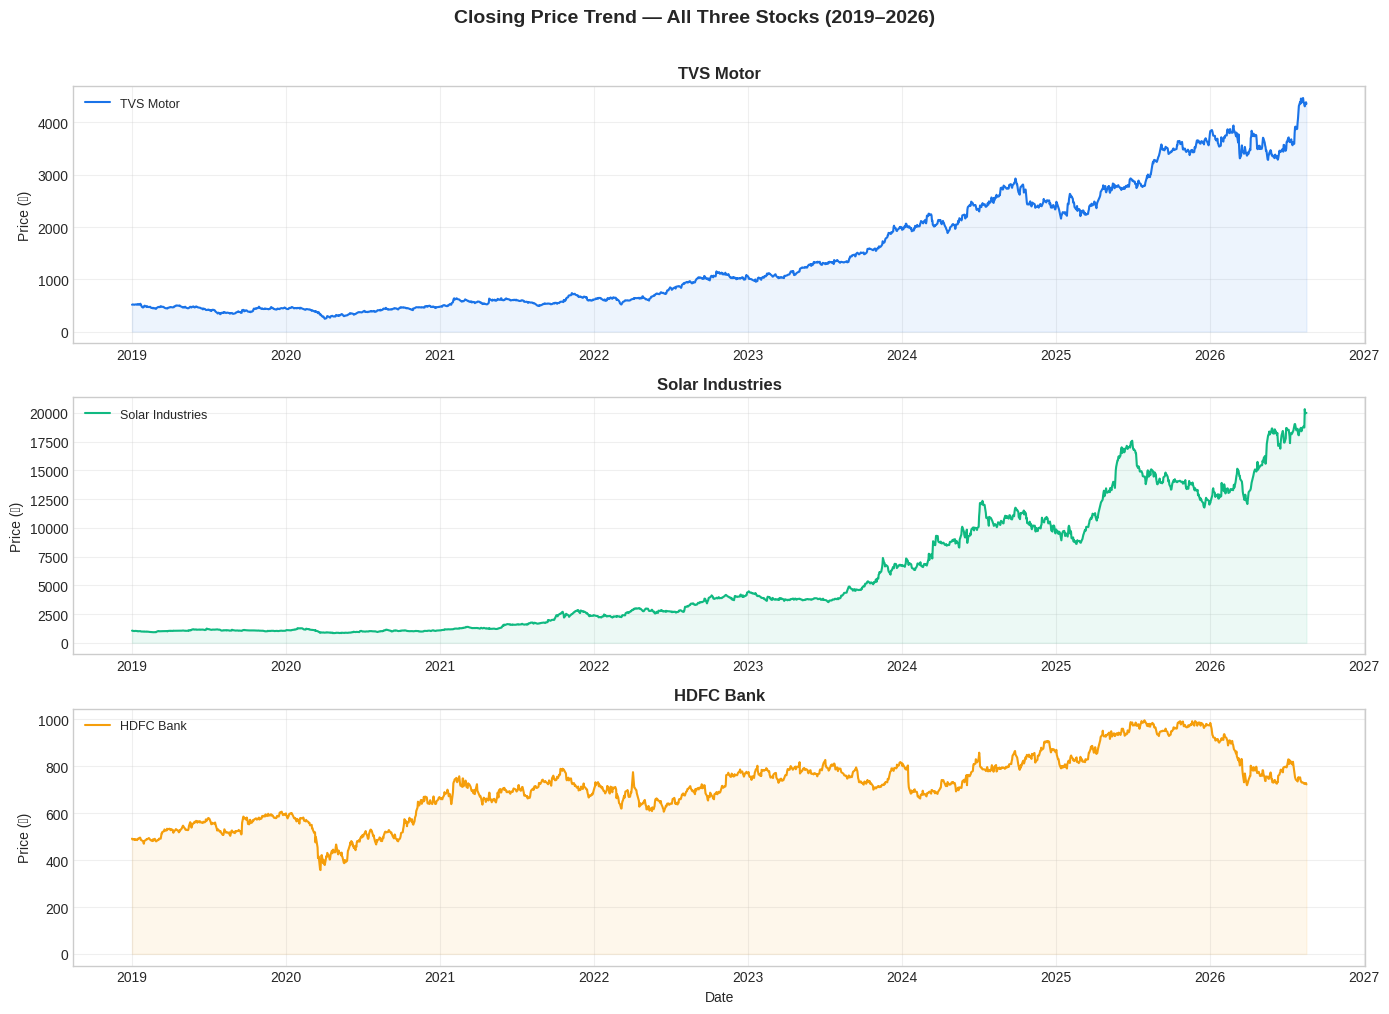

Chart 1 saved!


In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
fig.suptitle("Closing Price Trend — All Three Stocks (2019–2026)",
             fontsize=14, fontweight="bold", y=1.01)

stocks_list = [
    (tvs,   "TVS Motor",        "#1A73E8"),
    (solar, "Solar Industries", "#10B981"),
    (hdfc,  "HDFC Bank",        "#F59E0B"),
]

for ax, (df, name, color) in zip(axes, stocks_list):
    ax.plot(df.index, df["Close"], color=color,
            linewidth=1.5, label=name)
    ax.fill_between(df.index, df["Close"],
                    alpha=0.08, color=color)
    ax.set_title(name, fontsize=12, fontweight="bold")
    ax.set_ylabel("Price (₹)", fontsize=10)
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Date", fontsize=10)
plt.tight_layout()
plt.savefig("eda_closing_price_trend.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Chart 1 saved!")

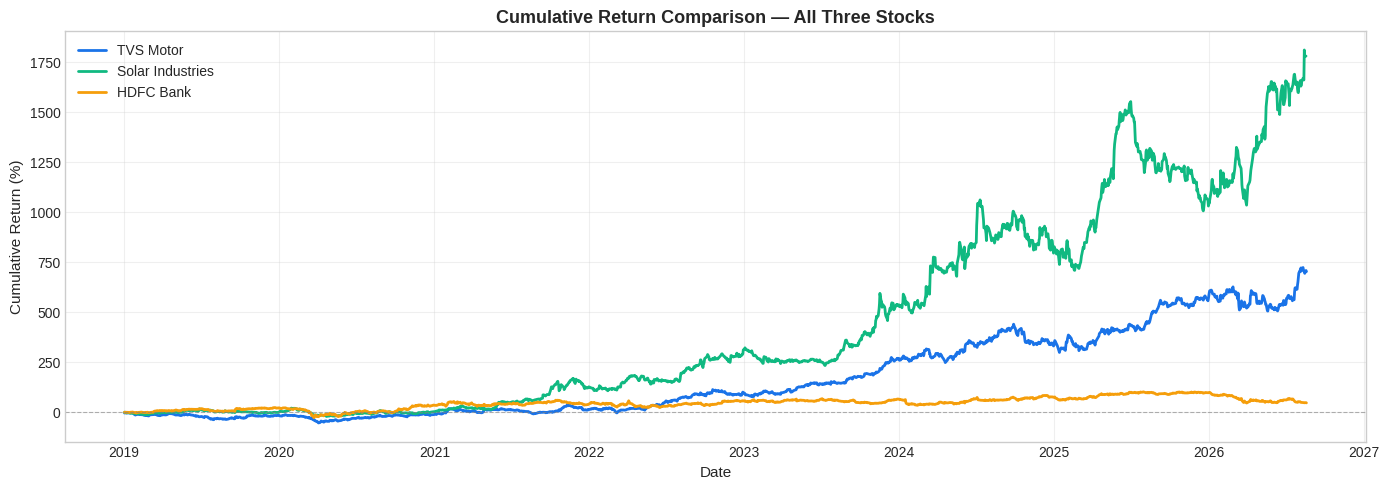

Chart 2 saved!


In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(tvs.index,   tvs["Cumulative_Return"]   * 100,
        color="#1A73E8", linewidth=2,   label="TVS Motor")
ax.plot(solar.index, solar["Cumulative_Return"] * 100,
        color="#10B981", linewidth=2,   label="Solar Industries")
ax.plot(hdfc.index,  hdfc["Cumulative_Return"]  * 100,
        color="#F59E0B", linewidth=2,   label="HDFC Bank")

ax.axhline(y=0, color="gray", linestyle="--",
           linewidth=0.8, alpha=0.6)
ax.set_title("Cumulative Return Comparison — All Three Stocks",
             fontsize=13, fontweight="bold")
ax.set_ylabel("Cumulative Return (%)", fontsize=11)
ax.set_xlabel("Date", fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("eda_cumulative_return.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Chart 2 saved!")

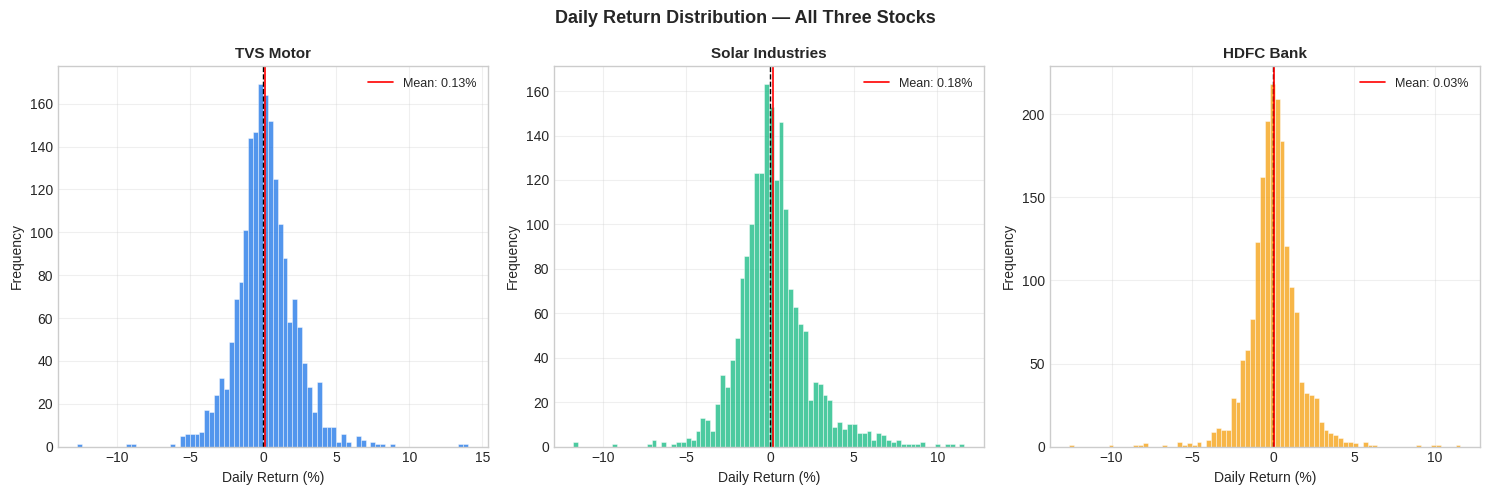

Chart 3 saved!


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Daily Return Distribution — All Three Stocks",
             fontsize=13, fontweight="bold")

for ax, (df, name, color) in zip(axes, stocks_list):
    ax.hist(df["Daily_Return"].dropna(), bins=80,
            color=color, alpha=0.75, edgecolor="white",
            linewidth=0.4)
    ax.axvline(x=0, color="black",
               linestyle="--", linewidth=1)
    ax.axvline(x=df["Daily_Return"].mean(),
               color="red", linestyle="-",
               linewidth=1.2,
               label=f"Mean: {df['Daily_Return'].mean():.2f}%")
    ax.set_title(name, fontsize=11, fontweight="bold")
    ax.set_xlabel("Daily Return (%)", fontsize=10)
    ax.set_ylabel("Frequency", fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("eda_daily_return_distribution.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Chart 3 saved!")

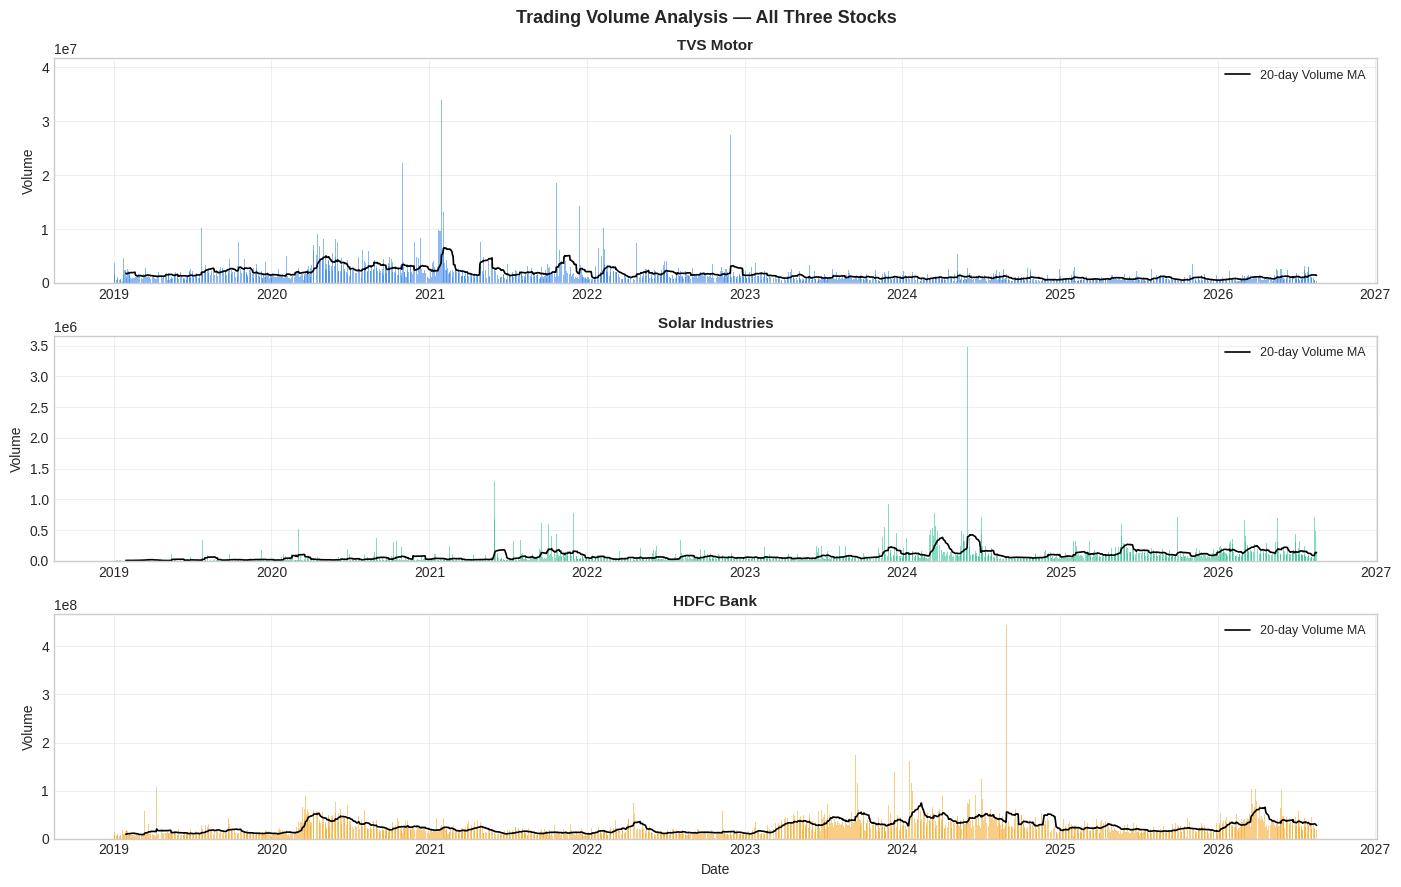

Chart 4 saved!


In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9))
fig.suptitle("Trading Volume Analysis — All Three Stocks",
             fontsize=13, fontweight="bold")

for ax, (df, name, color) in zip(axes, stocks_list):
    ax.bar(df.index, df["Volume"],
           color=color, alpha=0.5, width=1.5)
    vol_ma = df["Volume"].rolling(20).mean()
    ax.plot(df.index, vol_ma,
            color="black", linewidth=1.2,
            label="20-day Volume MA")
    ax.set_title(name, fontsize=11, fontweight="bold")
    ax.set_ylabel("Volume", fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Date", fontsize=10)
plt.tight_layout()
plt.savefig("eda_volume_analysis.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Chart 4 saved!")

In [ ]:
# Interactive candlestick — TVS Motor (last 6 months)
tvs_recent = tvs.last("6ME")

fig = make_subplots(rows=2, cols=1,
                    shared_xaxes=True,
                    row_heights=[0.75, 0.25],
                    vertical_spacing=0.03)

# Candlestick
fig.add_trace(go.Candlestick(
    x=tvs_recent.index,
    open=tvs_recent["Open"],
    high=tvs_recent["High"],
    low=tvs_recent["Low"],
    close=tvs_recent["Close"],
    name="TVS Motor",
    increasing_line_color="#10B981",
    decreasing_line_color="#EF4444"
), row=1, col=1)

# MA50
ma50 = tvs["Close"].rolling(50).mean()
fig.add_trace(go.Scatter(
    x=tvs_recent.index,
    y=ma50[tvs_recent.index],
    name="MA50", line=dict(color="#1A73E8",
                           width=1.5, dash="dash")
), row=1, col=1)

# MA200
ma200 = tvs["Close"].rolling(200).mean()
fig.add_trace(go.Scatter(
    x=tvs_recent.index,
    y=ma200[tvs_recent.index],
    name="MA200", line=dict(color="#F59E0B", width=1.5)
), row=1, col=1)

# Volume bars
fig.add_trace(go.Bar(
    x=tvs_recent.index,
    y=tvs_recent["Volume"],
    name="Volume",
    marker_color="#9CA3AF",
    opacity=0.5
), row=2, col=1)

fig.update_layout(
    title="TVS Motor — Candlestick Chart with MA50 & MA200 (Last 6 Months)",
    xaxis_rangeslider_visible=False,
    height=550,
    template="plotly_white",
    legend=dict(orientation="h", y=1.02)
)

fig.update_yaxes(title_text="Price (₹)", row=1, col=1)
fig.update_yaxes(title_text="Volume",    row=2, col=1)
fig.show()
print("Chart 5 — TVS Motor Candlestick done!")

Chart 5 — TVS Motor Candlestick done!


In [ ]:
solar_recent = solar.last("6ME")

fig2 = make_subplots(rows=2, cols=1,
                     shared_xaxes=True,
                     row_heights=[0.75, 0.25],
                     vertical_spacing=0.03)

fig2.add_trace(go.Candlestick(
    x=solar_recent.index,
    open=solar_recent["Open"],
    high=solar_recent["High"],
    low=solar_recent["Low"],
    close=solar_recent["Close"],
    name="Solar Industries",
    increasing_line_color="#10B981",
    decreasing_line_color="#EF4444"
), row=1, col=1)

ma50_s  = solar["Close"].rolling(50).mean()
ma200_s = solar["Close"].rolling(200).mean()

fig2.add_trace(go.Scatter(
    x=solar_recent.index,
    y=ma50_s[solar_recent.index],
    name="MA50",
    line=dict(color="#1A73E8", width=1.5, dash="dash")
), row=1, col=1)

fig2.add_trace(go.Scatter(
    x=solar_recent.index,
    y=ma200_s[solar_recent.index],
    name="MA200",
    line=dict(color="#F59E0B", width=1.5)
), row=1, col=1)

fig2.add_trace(go.Bar(
    x=solar_recent.index,
    y=solar_recent["Volume"],
    name="Volume",
    marker_color="#9CA3AF",
    opacity=0.5
), row=2, col=1)

fig2.update_layout(
    title="Solar Industries — Candlestick Chart with MA50 & MA200 (Last 6 Months)",
    xaxis_rangeslider_visible=False,
    height=550,
    template="plotly_white",
    legend=dict(orientation="h", y=1.02)
)

fig2.update_yaxes(title_text="Price (₹)", row=1, col=1)
fig2.update_yaxes(title_text="Volume",    row=2, col=1)
fig2.show()
print("Chart 6 — Solar Industries Candlestick done!")

Chart 6 — Solar Industries Candlestick done!


In [ ]:
hdfc_recent = hdfc.last("6ME")

fig3 = make_subplots(rows=2, cols=1,
                     shared_xaxes=True,
                     row_heights=[0.75, 0.25],
                     vertical_spacing=0.03)

fig3.add_trace(go.Candlestick(
    x=hdfc_recent.index,
    open=hdfc_recent["Open"],
    high=hdfc_recent["High"],
    low=hdfc_recent["Low"],
    close=hdfc_recent["Close"],
    name="HDFC Bank",
    increasing_line_color="#10B981",
    decreasing_line_color="#EF4444"
), row=1, col=1)

ma50_h  = hdfc["Close"].rolling(50).mean()
ma200_h = hdfc["Close"].rolling(200).mean()

fig3.add_trace(go.Scatter(
    x=hdfc_recent.index,
    y=ma50_h[hdfc_recent.index],
    name="MA50",
    line=dict(color="#1A73E8", width=1.5, dash="dash")
), row=1, col=1)

fig3.add_trace(go.Scatter(
    x=hdfc_recent.index,
    y=ma200_h[hdfc_recent.index],
    name="MA200",
    line=dict(color="#F59E0B", width=1.5)
), row=1, col=1)

fig3.add_trace(go.Bar(
    x=hdfc_recent.index,
    y=hdfc_recent["Volume"],
    name="Volume",
    marker_color="#9CA3AF",
    opacity=0.5
), row=2, col=1)

fig3.update_layout(
    title="HDFC Bank — Candlestick Chart with MA50 & MA200 (Last 6 Months)",
    xaxis_rangeslider_visible=False,
    height=550,
    template="plotly_white",
    legend=dict(orientation="h", y=1.02)
)

fig3.update_yaxes(title_text="Price (₹)", row=1, col=1)
fig3.update_yaxes(title_text="Volume",    row=2, col=1)
fig3.show()
print("Chart 7 — HDFC Bank Candlestick done!")

Chart 7 — HDFC Bank Candlestick done!


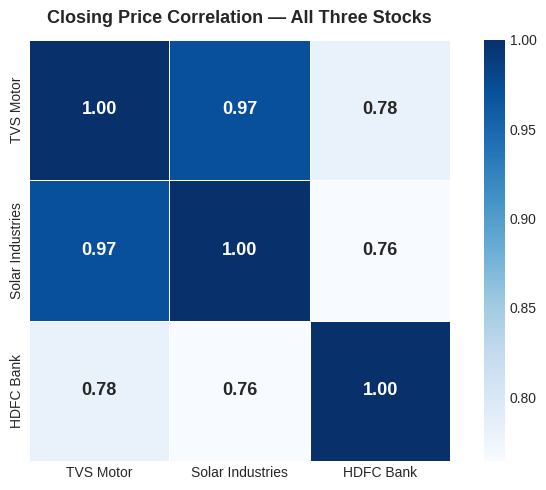

Chart 8 — Correlation heatmap done!


In [ ]:
# Combine closing prices of all 3 stocks
combined = pd.DataFrame({
    "TVS Motor"        : tvs["Close"],
    "Solar Industries" : solar["Close"],
    "HDFC Bank"        : hdfc["Close"]
})

# Calculate correlation
corr = combined.corr()

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr,
            annot=True,
            fmt=".2f",
            cmap="Blues",
            linewidths=0.5,
            square=True,
            ax=ax,
            annot_kws={"size": 13, "weight": "bold"})

ax.set_title("Closing Price Correlation — All Three Stocks",
             fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig("eda_correlation_heatmap.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Chart 8 — Correlation heatmap done!")

In [ ]:
print("=" * 55)
print("EDA SUMMARY STATISTICS")
print("=" * 55)

for name, df in [("TVS Motor", tvs),
                 ("Solar Industries", solar),
                 ("HDFC Bank", hdfc)]:
    print(f"\n--- {name} ---")
    print(f"  Date range     : {df.index[0].date()} "
          f"to {df.index[-1].date()}")
    print(f"  Total rows     : {len(df)}")
    print(f"  Avg Close      : Rs.{df['Close'].mean():.2f}")
    print(f"  Max Close      : Rs.{df['Close'].max():.2f}")
    print(f"  Min Close      : Rs.{df['Close'].min():.2f}")
    print(f"  Avg Daily Ret  : {df['Daily_Return'].mean():.3f}%")
    print(f"  Max Daily Ret  : {df['Daily_Return'].max():.2f}%")
    print(f"  Min Daily Ret  : {df['Daily_Return'].min():.2f}%")
    print(f"  Volatility     : "
          f"{df['Daily_Return'].std():.3f}% std dev")
    print(f"  Total Return   : "
          f"{df['Cumulative_Return'].iloc[-1]*100:.1f}%")

EDA SUMMARY STATISTICS

--- TVS Motor ---
  Date range     : 2019-01-02 to 2026-08-18
  Total rows     : 1887
  Avg Close      : Rs.1469.32
  Max Close      : Rs.4466.20
  Min Close      : Rs.245.87
  Avg Daily Ret  : 0.130%
  Max Daily Ret  : 14.04%
  Min Daily Ret  : -12.76%
  Volatility     : 2.004% std dev
  Total Return   : 702.8%

--- Solar Industries ---
  Date range     : 2019-01-02 to 2026-08-17
  Total rows     : 1885
  Avg Close      : Rs.5751.12
  Max Close      : Rs.20324.00
  Min Close      : Rs.837.29
  Avg Daily Ret  : 0.178%
  Max Daily Ret  : 11.62%
  Min Daily Ret  : -11.77%
  Volatility     : 2.135% std dev
  Total Return   : 1781.2%

--- HDFC Bank ---
  Date range     : 2019-01-02 to 2026-08-18
  Total rows     : 1887
  Avg Close      : Rs.713.53
  Max Close      : Rs.996.42
  Min Close      : Rs.357.66
  Avg Daily Ret  : 0.032%
  Max Daily Ret  : 11.60%
  Min Daily Ret  : -12.61%
  Volatility     : 1.569% std dev
  Total Return   : 45.7%


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Reload clean data
tvs   = pd.read_csv("stock_data_clean/TVS_Motor_clean.csv",
                     index_col=0, parse_dates=True)
solar = pd.read_csv("stock_data_clean/Solar_Industries_clean.csv",
                     index_col=0, parse_dates=True)
hdfc  = pd.read_csv("stock_data_clean/HDFC_Bank_clean.csv",
                     index_col=0, parse_dates=True)

# Convert to numeric
for df in [tvs, solar, hdfc]:
    for col in ["Open", "High", "Low", "Close", "Volume"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df.index = pd.to_datetime(df.index, errors="coerce")

print("Data reloaded successfully!")
print(f"TVS Motor        : {tvs.shape}")
print(f"Solar Industries : {solar.shape}")
print(f"HDFC Bank        : {hdfc.shape}")

Data reloaded successfully!
TVS Motor        : (1887, 8)
Solar Industries : (1885, 8)
HDFC Bank        : (1887, 8)


In [ ]:
def calculate_moving_averages(df):
    df["MA50"]  = df["Close"].rolling(window=50).mean()
    df["MA200"] = df["Close"].rolling(window=200).mean()
    # Golden cross signal
    # 1 = MA50 above MA200 (bullish)
    # 0 = MA50 below MA200 (bearish)
    df["Golden_Cross"] = (df["MA50"] > df["MA200"]).astype(int)
    return df

tvs   = calculate_moving_averages(tvs)
solar = calculate_moving_averages(solar)
hdfc  = calculate_moving_averages(hdfc)

print("Moving Averages calculated!")
print(f"\nTVS Motor sample:")
print(tvs[["Close", "MA50", "MA200",
           "Golden_Cross"]].dropna().tail(5))

Moving Averages calculated!

TVS Motor sample:
                  Close         MA50        MA200  Golden_Cross
Price                                                          
2026-08-12  4375.000000  3739.716001  3633.426085             1
2026-08-13  4342.200195  3759.310005  3637.000978             1
2026-08-14  4307.000000  3777.772007  3640.788013             1
2026-08-17  4385.899902  3799.138003  3645.283948             1
2026-08-18  4356.799805  3819.113999  3649.670258             1


In [ ]:
def calculate_RSI(df, period=14):
    delta = df["Close"].diff()

    gain  = delta.where(delta > 0, 0)
    loss  = -delta.where(delta < 0, 0)

    avg_gain = gain.rolling(window=period).mean()
    avg_loss = loss.rolling(window=period).mean()

    RS  = avg_gain / avg_loss
    RSI = 100 - (100 / (1 + RS))

    df["RSI"] = RSI
    return df

tvs   = calculate_RSI(tvs)
solar = calculate_RSI(solar)
hdfc  = calculate_RSI(hdfc)

print("RSI calculated!")
print(f"\nTVS Motor latest RSI:")
print(tvs[["Close", "RSI"]].dropna().tail(5))
print(f"\nSolar Industries latest RSI:")
print(solar[["Close", "RSI"]].dropna().tail(5))
print(f"\nHDFC Bank latest RSI:")
print(hdfc[["Close", "RSI"]].dropna().tail(5))

RSI calculated!

TVS Motor latest RSI:
                  Close        RSI
Price                             
2026-08-12  4375.000000  73.827445
2026-08-13  4342.200195  75.149186
2026-08-14  4307.000000  72.255515
2026-08-17  4385.899902  71.114917
2026-08-18  4356.799805  66.046535

Solar Industries latest RSI:
              Close        RSI
Price                         
2026-08-11  18770.0  48.488612
2026-08-12  18730.0  52.629367
2026-08-13  20324.0  74.552671
2026-08-14  19969.0  67.027708
2026-08-17  20000.0  74.200662

HDFC Bank latest RSI:
            Close        RSI
Price                       
2026-08-12  729.0  35.972313
2026-08-13  725.0  36.222901
2026-08-14  727.0  40.094708
2026-08-17  729.0  44.771218
2026-08-18  723.0  26.838208


In [ ]:
def calculate_MACD(df):
    EMA12 = df["Close"].ewm(span=12, adjust=False).mean()
    EMA26 = df["Close"].ewm(span=26, adjust=False).mean()

    df["MACD"]        = EMA12 - EMA26
    df["MACD_Signal"] = df["MACD"].ewm(
                        span=9, adjust=False).mean()
    df["MACD_Hist"]   = df["MACD"] - df["MACD_Signal"]
    return df

tvs   = calculate_MACD(tvs)
solar = calculate_MACD(solar)
hdfc  = calculate_MACD(hdfc)

print("MACD calculated!")
print(f"\nTVS Motor latest MACD:")
print(tvs[["Close", "MACD",
           "MACD_Signal", "MACD_Hist"]].tail(5))

MACD calculated!

TVS Motor latest MACD:
                  Close        MACD  MACD_Signal  MACD_Hist
Price                                                      
2026-08-12  4375.000000  214.192858   199.755606  14.437251
2026-08-13  4342.200195  202.475976   200.299680   2.176295
2026-08-14  4307.000000  188.180671   197.875878  -9.695207
2026-08-17  4385.899902  181.130146   194.526732 -13.396586
2026-08-18  4356.799805  171.220695   189.865525 -18.644830


In [ ]:
def calculate_Bollinger(df, period=20):
    df["BB_Mid"]   = df["Close"].rolling(window=period).mean()
    std            = df["Close"].rolling(window=period).std()
    df["BB_Upper"] = df["BB_Mid"] + (2 * std)
    df["BB_Lower"] = df["BB_Mid"] - (2 * std)
    df["BB_Width"] = df["BB_Upper"] - df["BB_Lower"]

    # Position of price within bands (0 = lower, 1 = upper)
    df["BB_Position"] = ((df["Close"] - df["BB_Lower"]) /
                          df["BB_Width"])
    return df

tvs   = calculate_Bollinger(tvs)
solar = calculate_Bollinger(solar)
hdfc  = calculate_Bollinger(hdfc)

print("Bollinger Bands calculated!")
print(f"\nTVS Motor latest Bollinger Bands:")
print(tvs[["Close", "BB_Upper",
           "BB_Mid", "BB_Lower",
           "BB_Position"]].dropna().tail(5))

Bollinger Bands calculated!

TVS Motor latest Bollinger Bands:
                  Close     BB_Upper       BB_Mid     BB_Lower  BB_Position
Price                                                                      
2026-08-12  4375.000000  4729.438473  4099.490015  3469.541556     0.718677
2026-08-13  4342.200195  4723.551331  4138.425024  3553.298718     0.674129
2026-08-14  4307.000000  4708.015157  4172.865027  3637.714897     0.625325
2026-08-17  4385.899902  4679.342810  4212.650024  3745.957239     0.685614
2026-08-18  4356.799805  4666.996751  4240.890015  3814.783278     0.636010


In [ ]:
def calculate_volume_ma(df, period=20):
    df["Volume_MA"]    = df["Volume"].rolling(
                          window=period).mean()
    # Volume ratio — is today's volume above average?
    df["Volume_Ratio"] = df["Volume"] / df["Volume_MA"]
    return df

tvs   = calculate_volume_ma(tvs)
solar = calculate_volume_ma(solar)
hdfc  = calculate_volume_ma(hdfc)

print("Volume MA calculated!")
print(f"\nTVS Motor latest Volume data:")
print(tvs[["Volume", "Volume_MA",
           "Volume_Ratio"]].dropna().tail(5))

Volume MA calculated!

TVS Motor latest Volume data:
            Volume   Volume_MA  Volume_Ratio
Price                                       
2026-08-12  911635  1524376.65      0.598038
2026-08-13  533564  1490590.95      0.357955
2026-08-14  560053  1477310.55      0.379103
2026-08-17  604301  1485607.95      0.406770
2026-08-18  444890  1388297.60      0.320457


In [ ]:
def calculate_returns(df):
    if "Daily_Return" not in df.columns:
        df["Daily_Return"] = df["Close"].pct_change() * 100
    if "Cumulative_Return" not in df.columns:
        df["Cumulative_Return"] = (
            1 + df["Daily_Return"] / 100).cumprod() - 1
    return df

tvs   = calculate_returns(tvs)
solar = calculate_returns(solar)
hdfc  = calculate_returns(hdfc)

print("Returns confirmed!")

Returns confirmed!


In [ ]:
def generate_labels(df, forward_days=5, threshold=0.02):
    # Calculate forward return
    # How much will price change in next 5 days?
    df["Future_Return"] = (df["Close"].shift(-forward_days)
                           - df["Close"]) / df["Close"]

    # Generate signal based on forward return
    df["Signal"] = 1  # Default HOLD

    # BUY if price rises more than 2% in next 5 days
    df.loc[df["Future_Return"] >  threshold, "Signal"] = 2

    # SELL if price falls more than 2% in next 5 days
    df.loc[df["Future_Return"] < -threshold, "Signal"] = 0

    return df

tvs   = generate_labels(tvs)
solar = generate_labels(solar)
hdfc  = generate_labels(hdfc)

print("BUY / HOLD / SELL Labels generated!\n")

# Check label distribution
label_map = {0: "SELL", 1: "HOLD", 2: "BUY"}

for name, df in [("TVS Motor", tvs),
                 ("Solar Industries", solar),
                 ("HDFC Bank", hdfc)]:
    counts = df["Signal"].value_counts().sort_index()
    total  = counts.sum()
    print(f"--- {name} ---")
    for label, count in counts.items():
        print(f"  {label_map[label]:4s} : "
              f"{count:4d} ({count/total*100:.1f}%)")
    print()

BUY / HOLD / SELL Labels generated!

--- TVS Motor ---
  SELL :  498 (26.4%)
  HOLD :  740 (39.2%)
  BUY  :  649 (34.4%)

--- Solar Industries ---
  SELL :  496 (26.3%)
  HOLD :  718 (38.1%)
  BUY  :  671 (35.6%)

--- HDFC Bank ---
  SELL :  391 (20.7%)
  HOLD : 1041 (55.2%)
  BUY  :  455 (24.1%)



In [ ]:
print("=== FEATURE ENGINEERING SUMMARY ===\n")

all_features = [
    "Close", "MA50", "MA200", "Golden_Cross",
    "RSI", "MACD", "MACD_Signal", "MACD_Hist",
    "BB_Upper", "BB_Mid", "BB_Lower",
    "BB_Width", "BB_Position",
    "Volume_MA", "Volume_Ratio",
    "Daily_Return", "Signal"
]

for name, df in [("TVS Motor", tvs),
                 ("Solar Industries", solar),
                 ("HDFC Bank", hdfc)]:
    print(f"--- {name} ---")
    print(f"  Total columns  : {len(df.columns)}")
    missing = df[all_features].isnull().sum()
    print(f"  Missing values : {missing.sum()}")
    print(f"  Total rows     : {len(df)}")
    print()

print("All features present!")
print(f"\nFull column list:")
print(tvs.columns.tolist())

=== FEATURE ENGINEERING SUMMARY ===

--- TVS Motor ---
  Total columns  : 24
  Missing values : 394
  Total rows     : 1887

--- Solar Industries ---
  Total columns  : 24
  Missing values : 394
  Total rows     : 1885

--- HDFC Bank ---
  Total columns  : 24
  Missing values : 394
  Total rows     : 1887

All features present!

Full column list:
['Open', 'High', 'Low', 'Close', 'Volume', 'Stock', 'Daily_Return', 'Cumulative_Return', 'MA50', 'MA200', 'Golden_Cross', 'RSI', 'MACD', 'MACD_Signal', 'MACD_Hist', 'BB_Mid', 'BB_Upper', 'BB_Lower', 'BB_Width', 'BB_Position', 'Volume_MA', 'Volume_Ratio', 'Future_Return', 'Signal']


In [ ]:
import os
os.makedirs("stock_data_features", exist_ok=True)

tvs.to_csv("stock_data_features/TVS_Motor_features.csv")
solar.to_csv(
    "stock_data_features/Solar_Industries_features.csv")
hdfc.to_csv("stock_data_features/HDFC_Bank_features.csv")

# Save master
master_features = pd.concat([tvs, solar, hdfc])
master_features.to_csv(
    "stock_data_features/ALL_STOCKS_features.csv")

print("Feature engineered files saved!")
print(f"\nTotal rows in master : {len(master_features)}")
print(f"\nRows per stock:")
print(master_features["Stock"].value_counts())

Feature engineered files saved!

Total rows in master : 5659

Rows per stock:
Stock
TVS Motor           1887
HDFC Bank           1887
Solar Industries    1885
Name: count, dtype: int64


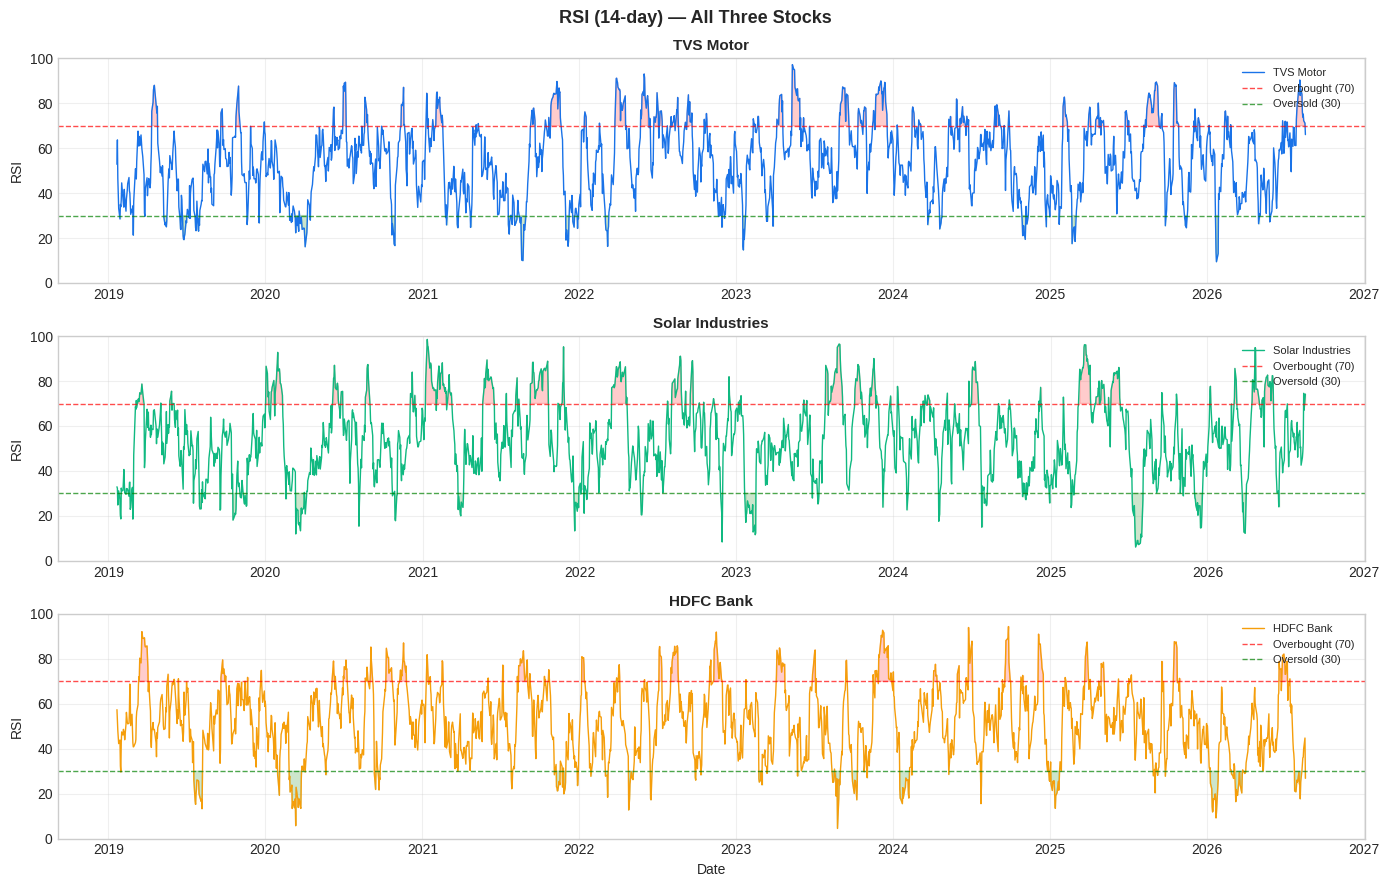

RSI chart saved!


In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9))
fig.suptitle("RSI (14-day) — All Three Stocks",
             fontsize=13, fontweight="bold")

stocks_list = [
    (tvs,   "TVS Motor",        "#1A73E8"),
    (solar, "Solar Industries", "#10B981"),
    (hdfc,  "HDFC Bank",        "#F59E0B"),
]

for ax, (df, name, color) in zip(axes, stocks_list):
    ax.plot(df.index, df["RSI"],
            color=color, linewidth=1, label=name)
    ax.axhline(y=70, color="red",
               linestyle="--", linewidth=1,
               alpha=0.7, label="Overbought (70)")
    ax.axhline(y=30, color="green",
               linestyle="--", linewidth=1,
               alpha=0.7, label="Oversold (30)")
    ax.fill_between(df.index, df["RSI"], 70,
                    where=(df["RSI"] >= 70),
                    alpha=0.2, color="red")
    ax.fill_between(df.index, df["RSI"], 30,
                    where=(df["RSI"] <= 30),
                    alpha=0.2, color="green")
    ax.set_title(name, fontsize=11, fontweight="bold")
    ax.set_ylabel("RSI", fontsize=10)
    ax.set_ylim(0, 100)
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Date", fontsize=10)
plt.tight_layout()
plt.savefig("feature_rsi_plot.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("RSI chart saved!")

MODEL TRAINING

In [ ]:
# Install required libraries
!pip install scikit-learn statsmodels tensorflow shap --quiet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Scikit-learn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (accuracy_score,
                             classification_report,
                             confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight

# Statsmodels for ARIMA
from statsmodels.tsa.arima.model import ARIMA

# TensorFlow / Keras for LSTM
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (LSTM, Dense,
                                     Dropout)
from tensorflow.keras.callbacks import EarlyStopping

# Save models
import joblib
import os

os.makedirs("models", exist_ok=True)

print("All ML libraries imported successfully!")
print(f"TensorFlow version : {tf.__version__}")

All ML libraries imported successfully!
TensorFlow version : 2.20.0


In [ ]:
tvs   = pd.read_csv(
    "stock_data_features/TVS_Motor_features.csv",
    index_col=0, parse_dates=True)
solar = pd.read_csv(
    "stock_data_features/Solar_Industries_features.csv",
    index_col=0, parse_dates=True)
hdfc  = pd.read_csv(
    "stock_data_features/HDFC_Bank_features.csv",
    index_col=0, parse_dates=True)

for df in [tvs, solar, hdfc]:
    for col in ["Open","High","Low","Close","Volume",
                "MA50","MA200","RSI","MACD",
                "MACD_Signal","MACD_Hist",
                "BB_Upper","BB_Mid","BB_Lower",
                "BB_Width","BB_Position",
                "Volume_MA","Volume_Ratio",
                "Daily_Return","Golden_Cross"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col],
                                    errors="coerce")

print("Feature data reloaded!")
print(f"TVS Motor        : {tvs.shape}")
print(f"Solar Industries : {solar.shape}")
print(f"HDFC Bank        : {hdfc.shape}")

Feature data reloaded!
TVS Motor        : (1887, 24)
Solar Industries : (1885, 24)
HDFC Bank        : (1887, 24)


In [ ]:
# These are the features the Random Forest will use
FEATURE_COLS = [
    "MA50", "MA200", "Golden_Cross",
    "RSI",
    "MACD", "MACD_Signal", "MACD_Hist",
    "BB_Upper", "BB_Mid", "BB_Lower",
    "BB_Width", "BB_Position",
    "Volume_MA", "Volume_Ratio",
    "Daily_Return"
]

TARGET_COL = "Signal"

def prepare_rf_data(df, name):
    # Drop rows with any missing values in features
    data = df[FEATURE_COLS + [TARGET_COL]].dropna()

    X = data[FEATURE_COLS]
    y = data[TARGET_COL].astype(int)

    # Split keeping chronological order — NO shuffle
    split_70 = int(len(data) * 0.70)
    split_85 = int(len(data) * 0.85)

    X_train = X.iloc[:split_70]
    X_val   = X.iloc[split_70:split_85]
    X_test  = X.iloc[split_85:]

    y_train = y.iloc[:split_70]
    y_val   = y.iloc[split_70:split_85]
    y_test  = y.iloc[split_85:]

    print(f"\n{name} data split:")
    print(f"  Train : {len(X_train)} rows")
    print(f"  Val   : {len(X_val)} rows")
    print(f"  Test  : {len(X_test)} rows")

    return X_train, X_val, X_test, y_train, y_val, y_test

tvs_Xtr,  tvs_Xv,  tvs_Xte,  tvs_ytr,  tvs_yv,  tvs_yte  = prepare_rf_data(tvs,   "TVS Motor")
sol_Xtr,  sol_Xv,  sol_Xte,  sol_ytr,  sol_yv,  sol_yte  = prepare_rf_data(solar, "Solar Industries")
hdf_Xtr,  hdf_Xv,  hdf_Xte,  hdf_ytr,  hdf_yv,  hdf_yte  = prepare_rf_data(hdfc,  "HDFC Bank")


TVS Motor data split:
  Train : 1181 rows
  Val   : 253 rows
  Test  : 254 rows

Solar Industries data split:
  Train : 1180 rows
  Val   : 253 rows
  Test  : 253 rows

HDFC Bank data split:
  Train : 1181 rows
  Val   : 253 rows
  Test  : 254 rows


In [ ]:
# FIXED Random Forest Training
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import joblib

FEATURE_COLS = [
    "MA50", "MA200", "Golden_Cross",
    "RSI",
    "MACD", "MACD_Signal", "MACD_Hist",
    "BB_Upper", "BB_Mid", "BB_Lower",
    "BB_Width", "BB_Position",
    "Volume_MA", "Volume_Ratio",
    "Daily_Return"
]

TARGET_COL = "Signal"

def train_rf_fixed(df, name):
    print(f"\nTraining Random Forest — {name}...")

    # Drop ALL rows with any NaN — critical fix
    data = df[FEATURE_COLS + [TARGET_COL]].dropna()
    data = data[data[TARGET_COL].isin([0, 1, 2])]

    print(f"  Rows after dropna : {len(data)}")

    X = data[FEATURE_COLS].astype(float)
    y = data[TARGET_COL].astype(int)

    # Chronological split — no shuffle
    split_70 = int(len(data) * 0.70)
    split_85 = int(len(data) * 0.85)

    X_train = X.iloc[:split_70]
    X_test  = X.iloc[split_85:]
    y_train = y.iloc[:split_70]
    y_test  = y.iloc[split_85:]

    print(f"  Train : {len(X_train)} | Test : {len(X_test)}")

    # Class weights to handle imbalance
    classes = np.array([0, 1, 2])
    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_train)
    class_weight_dict = dict(zip(classes, weights))

    # Train
    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=3,
        min_samples_split=5,
        class_weight=class_weight_dict,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)

    # Evaluate
    y_pred   = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    print(f"  Accuracy : {accuracy*100:.2f}%")
    print(f"\n  Classification Report:")
    print(classification_report(
        y_test, y_pred,
        target_names=["SELL", "HOLD", "BUY"]))

    return model, X_test, y_test

# Train all 3 stocks
rf_tvs,   tvs_Xte,  tvs_yte  = train_rf_fixed(tvs,   "TVS Motor")
rf_solar, sol_Xte,  sol_yte  = train_rf_fixed(solar, "Solar Industries")
rf_hdfc,  hdf_Xte,  hdf_yte  = train_rf_fixed(hdfc,  "HDFC Bank")

# Save fixed models
joblib.dump(rf_tvs,   "models/rf_tvs_motor.pkl")
joblib.dump(rf_solar, "models/rf_solar_industries.pkl")
joblib.dump(rf_hdfc,  "models/rf_hdfc_bank.pkl")

print("\nFixed Random Forest models saved!")


Training Random Forest — TVS Motor...
  Rows after dropna : 1688
  Train : 1181 | Test : 254
  Accuracy : 39.76%

  Classification Report:
              precision    recall  f1-score   support

        SELL       0.36      0.53      0.43        57
        HOLD       0.60      0.27      0.38       121
         BUY       0.33      0.50      0.40        76

    accuracy                           0.40       254
   macro avg       0.43      0.43      0.40       254
weighted avg       0.46      0.40      0.39       254


Training Random Forest — Solar Industries...
  Rows after dropna : 1686
  Train : 1180 | Test : 253
  Accuracy : 31.23%

  Classification Report:
              precision    recall  f1-score   support

        SELL       0.28      0.85      0.42        73
        HOLD       0.00      0.00      0.00        93
         BUY       0.50      0.20      0.28        87

    accuracy                           0.31       253
   macro avg       0.26      0.35      0.24       253
weight

In [ ]:
joblib.dump(rf_tvs,   "models/rf_tvs_motor.pkl")
joblib.dump(rf_solar, "models/rf_solar_industries.pkl")
joblib.dump(rf_hdfc,  "models/rf_hdfc_bank.pkl")

print("Random Forest models saved!")
print("  models/rf_tvs_motor.pkl")
print("  models/rf_solar_industries.pkl")
print("  models/rf_hdfc_bank.pkl")

Random Forest models saved!
  models/rf_tvs_motor.pkl
  models/rf_solar_industries.pkl
  models/rf_hdfc_bank.pkl


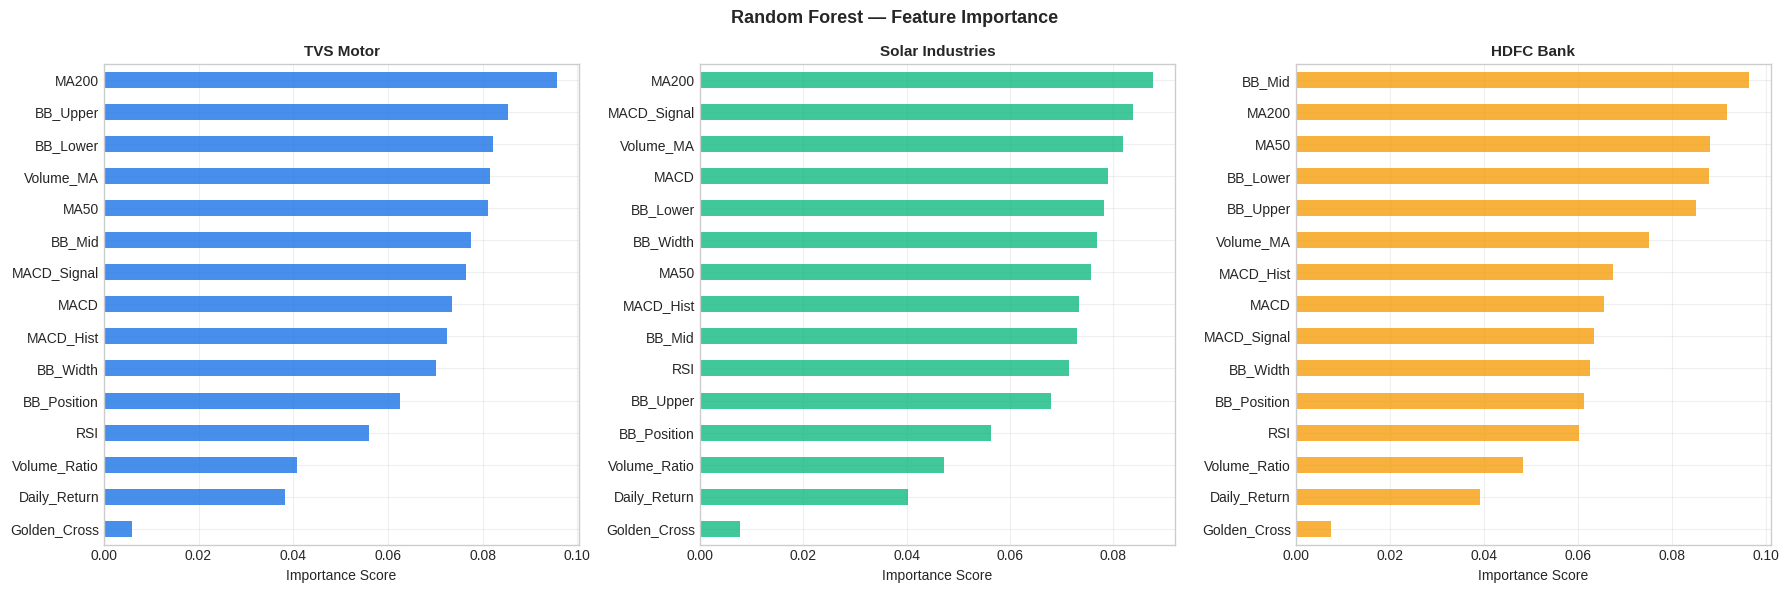

Feature importance chart saved!


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Random Forest — Feature Importance",
             fontsize=13, fontweight="bold")

models_list = [
    (rf_tvs,   "TVS Motor",        "#1A73E8"),
    (rf_solar, "Solar Industries", "#10B981"),
    (rf_hdfc,  "HDFC Bank",        "#F59E0B"),
]

for ax, (model, name, color) in zip(axes, models_list):
    importances = pd.Series(
        model.feature_importances_,
        index=FEATURE_COLS
    ).sort_values(ascending=True)

    importances.plot(kind="barh", ax=ax,
                     color=color, alpha=0.8)
    ax.set_title(name, fontsize=11,
                 fontweight="bold")
    ax.set_xlabel("Importance Score", fontsize=10)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("feature_importance.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Feature importance chart saved!")

In [ ]:
def train_arima(df, name):
    print(f"\nTraining ARIMA — {name}...")

    # Use closing price series
    close_series = df["Close"].dropna()

    # Train on 85% of data
    split = int(len(close_series) * 0.85)
    train = close_series.iloc[:split]
    test  = close_series.iloc[split:]

    # Fit ARIMA(5,1,0)
    model = ARIMA(train, order=(5, 1, 0))
    fitted = model.fit()

    # Forecast next 30 days
    forecast = fitted.forecast(steps=30)

    print(f"  Train size     : {len(train)}")
    print(f"  Test size      : {len(test)}")
    print(f"  AIC score      : {fitted.aic:.2f}")
    print(f"  Forecast range : "
          f"Rs.{forecast.min():.2f} "
          f"to Rs.{forecast.max():.2f}")

    return fitted, forecast

arima_tvs,   forecast_tvs   = train_arima(tvs,   "TVS Motor")
arima_solar, forecast_solar = train_arima(solar, "Solar Industries")
arima_hdfc,  forecast_hdfc  = train_arima(hdfc,  "HDFC Bank")


Training ARIMA — TVS Motor...


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

A date index has been provided, but it ha

  Train size     : 1603
  Test size      : 284
  AIC score      : 14682.93
  Forecast range : Rs.2903.48 to Rs.2908.41

Training ARIMA — Solar Industries...
  Train size     : 1602
  Test size      : 283
  AIC score      : 20166.88
  Forecast range : Rs.17485.50 to Rs.17525.53

Training ARIMA — HDFC Bank...
  Train size     : 1603
  Test size      : 284
  AIC score      : 11976.81
  Forecast range : Rs.981.51 to Rs.983.37


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



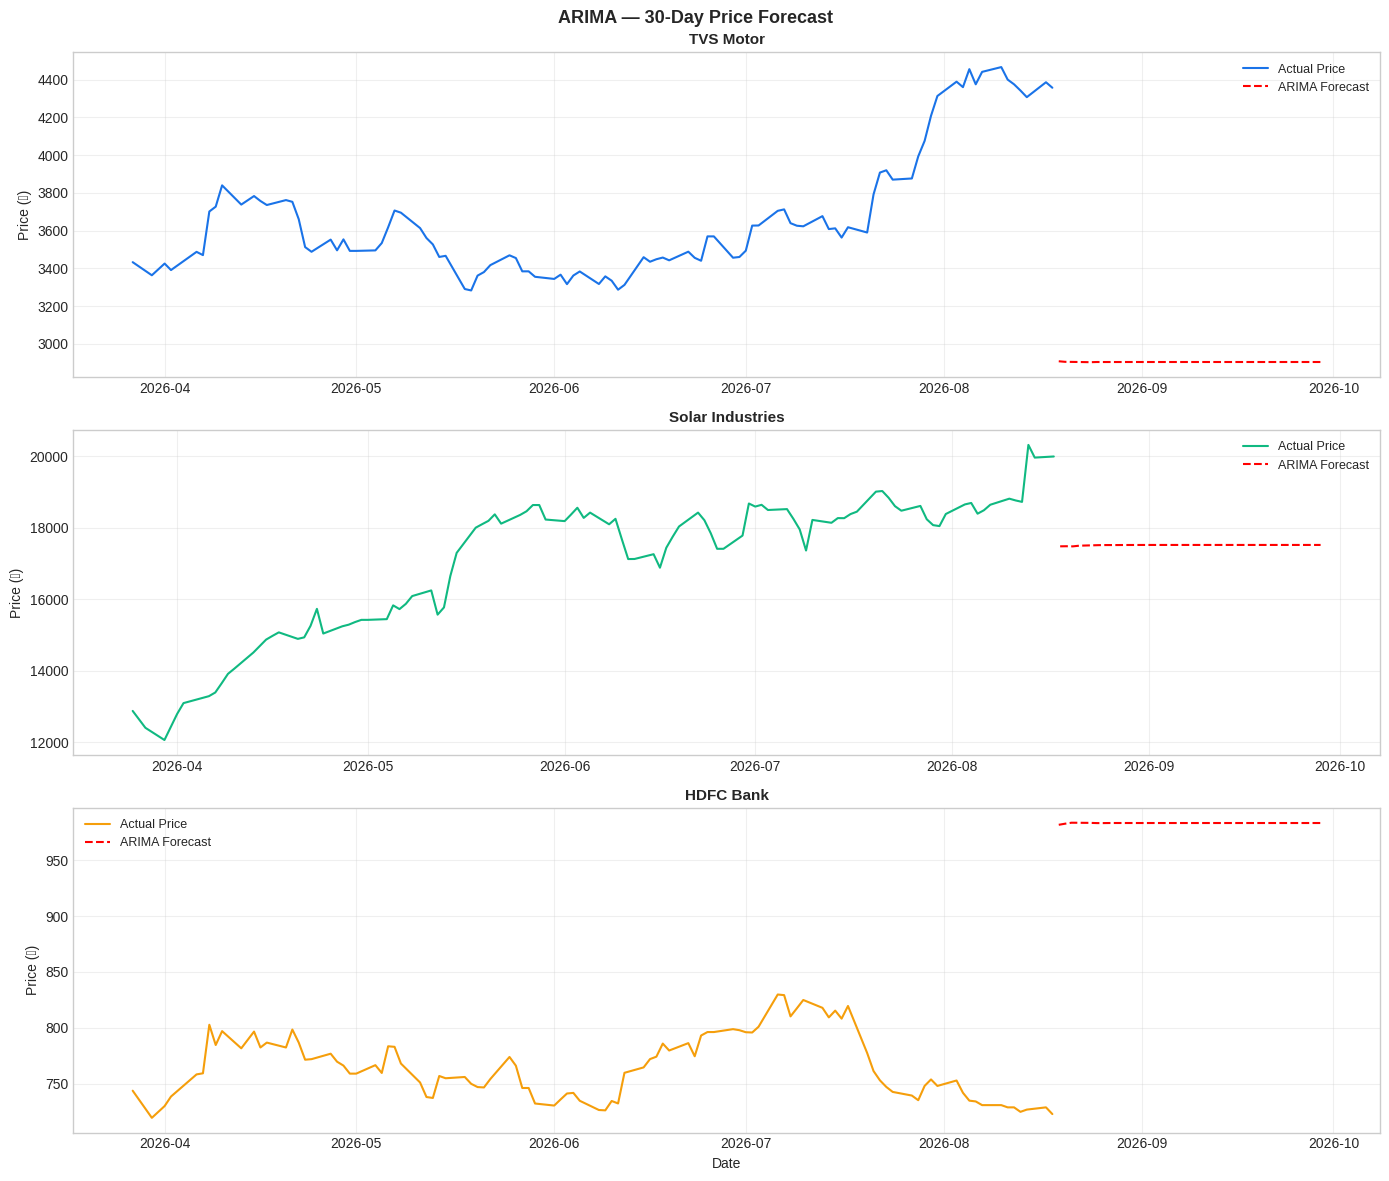

ARIMA forecast chart saved!


In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
fig.suptitle("ARIMA — 30-Day Price Forecast",
             fontsize=13, fontweight="bold")

data_list = [
    (tvs,   forecast_tvs,   "TVS Motor",        "#1A73E8"),
    (solar, forecast_solar, "Solar Industries", "#10B981"),
    (hdfc,  forecast_hdfc,  "HDFC Bank",        "#F59E0B"),
]

for ax, (df, forecast, name, color) in zip(axes,
                                            data_list):
    # Plot last 100 days of actual price
    last_100 = df["Close"].dropna().tail(100)
    ax.plot(last_100.index, last_100.values,
            color=color, linewidth=1.5,
            label="Actual Price")

    # Plot forecast as dashed line
    forecast_index = pd.date_range(
        start=last_100.index[-1],
        periods=31, freq="B")[1:]
    ax.plot(forecast_index, forecast.values,
            color="red", linewidth=1.5,
            linestyle="--", label="ARIMA Forecast")

    ax.set_title(name, fontsize=11,
                 fontweight="bold")
    ax.set_ylabel("Price (₹)", fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Date", fontsize=10)
plt.tight_layout()
plt.savefig("arima_forecast.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("ARIMA forecast chart saved!")

In [ ]:
def prepare_lstm_data(df, sequence_length=60):
    # Use only closing price for LSTM
    close_data = df["Close"].dropna().values.reshape(-1, 1)

    # Scale to 0-1 range
    scaler = MinMaxScaler(feature_range=(0, 1))
    scaled = scaler.fit_transform(close_data)

    # Create sequences
    X, y = [], []
    for i in range(sequence_length, len(scaled)):
        X.append(scaled[i-sequence_length:i, 0])
        y.append(scaled[i, 0])

    X = np.array(X)
    y = np.array(y)

    # Reshape for LSTM input (samples, timesteps, features)
    X = X.reshape(X.shape[0], X.shape[1], 1)

    # Split 85/15
    split = int(len(X) * 0.85)
    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]

    return X_train, X_test, y_train, y_test, scaler

print("Preparing LSTM data...")
tvs_Xl_tr,  tvs_Xl_te,  tvs_yl_tr,  tvs_yl_te,  scaler_tvs   = prepare_lstm_data(tvs)
sol_Xl_tr,  sol_Xl_te,  sol_yl_tr,  sol_yl_te,  scaler_solar = prepare_lstm_data(solar)
hdf_Xl_tr,  hdf_Xl_te,  hdf_yl_tr,  hdf_yl_te,  scaler_hdfc  = prepare_lstm_data(hdfc)

print(f"TVS Motor LSTM    : Train {tvs_Xl_tr.shape} Test {tvs_Xl_te.shape}")
print(f"Solar Ind LSTM    : Train {sol_Xl_tr.shape} Test {sol_Xl_te.shape}")
print(f"HDFC Bank LSTM    : Train {hdf_Xl_tr.shape} Test {hdf_Xl_te.shape}")

Preparing LSTM data...
TVS Motor LSTM    : Train (1552, 60, 1) Test (275, 60, 1)
Solar Ind LSTM    : Train (1551, 60, 1) Test (274, 60, 1)
HDFC Bank LSTM    : Train (1552, 60, 1) Test (275, 60, 1)


In [ ]:
def build_and_train_lstm(X_train, y_train,
                          X_test, y_test,
                          name, scaler):
    print(f"\nBuilding LSTM — {name}...")

    # Build model
    model = Sequential([
        LSTM(50, return_sequences=True,
             input_shape=(X_train.shape[1], 1)),
        Dropout(0.2),
        LSTM(50, return_sequences=False),
        Dropout(0.2),
        Dense(25),
        Dense(1)
    ])

    model.compile(optimizer="adam", loss="mse")

    # Early stopping to prevent overfitting
    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True)

    # Train
    history = model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=32,
        validation_data=(X_test, y_test),
        callbacks=[early_stop],
        verbose=0
    )

    # Evaluate
    test_pred   = model.predict(X_test, verbose=0)

    # Inverse scale to get actual prices
    test_pred_actual = scaler.inverse_transform(
        test_pred)
    y_test_actual    = scaler.inverse_transform(
        y_test.reshape(-1, 1))

    # Calculate RMSE
    rmse = np.sqrt(np.mean(
        (test_pred_actual - y_test_actual) ** 2))
    mape = np.mean(np.abs(
        (y_test_actual - test_pred_actual)
        / y_test_actual)) * 100

    print(f"  Epochs trained : {len(history.history['loss'])}")
    print(f"  RMSE           : Rs.{rmse:.2f}")
    print(f"  MAPE           : {mape:.2f}%")

    return model, history, rmse, mape

print("Training LSTM models — this may take 2-3 minutes...")

lstm_tvs,   hist_tvs,   rmse_tvs,   mape_tvs   = build_and_train_lstm(
    tvs_Xl_tr, tvs_yl_tr,
    tvs_Xl_te, tvs_yl_te,
    "TVS Motor", scaler_tvs)

lstm_solar, hist_solar, rmse_solar, mape_solar = build_and_train_lstm(
    sol_Xl_tr, sol_yl_tr,
    sol_Xl_te, sol_yl_te,
    "Solar Industries", scaler_solar)

lstm_hdfc,  hist_hdfc,  rmse_hdfc,  mape_hdfc  = build_and_train_lstm(
    hdf_Xl_tr, hdf_yl_tr,
    hdf_Xl_te, hdf_yl_te,
    "HDFC Bank", scaler_hdfc)


Training LSTM models — this may take 2-3 minutes...

Building LSTM — TVS Motor...
  Epochs trained : 7
  RMSE           : Rs.150.75
  MAPE           : 3.19%

Building LSTM — Solar Industries...
  Epochs trained : 21
  RMSE           : Rs.584.22
  MAPE           : 2.96%

Building LSTM — HDFC Bank...
  Epochs trained : 50
  RMSE           : Rs.13.37
  MAPE           : 1.18%


In [ ]:
# Save in newer Keras format — no warning
lstm_tvs.save("models/lstm_tvs_motor.keras")
lstm_solar.save("models/lstm_solar_industries.keras")
lstm_hdfc.save("models/lstm_hdfc_bank.keras")

# Save scalers
joblib.dump(scaler_tvs,   "models/scaler_tvs.pkl")
joblib.dump(scaler_solar, "models/scaler_solar.pkl")
joblib.dump(scaler_hdfc,  "models/scaler_hdfc.pkl")

print("LSTM models and scalers saved!")

LSTM models and scalers saved!


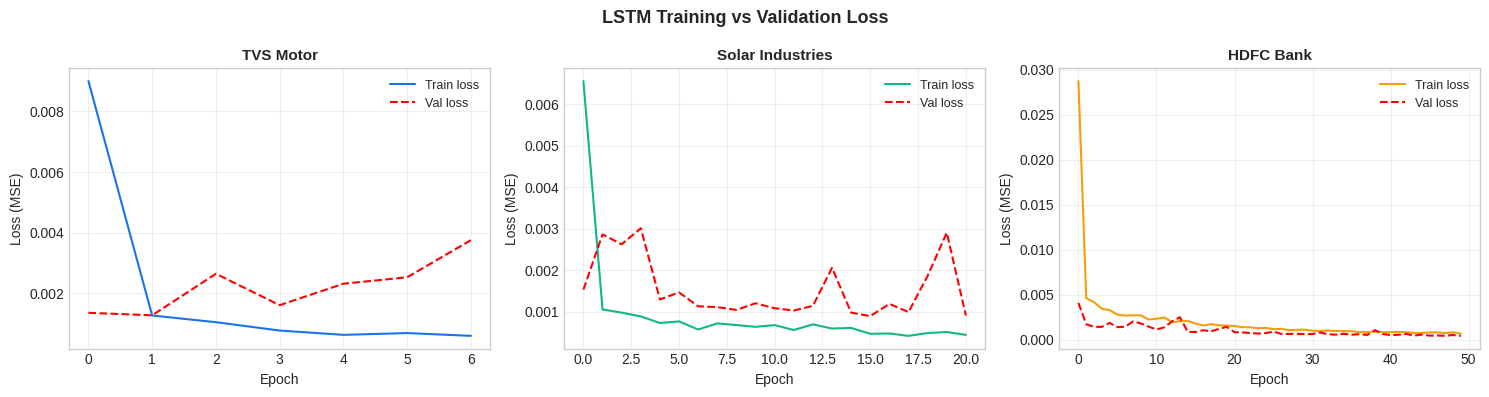

LSTM loss chart saved!


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("LSTM Training vs Validation Loss",
             fontsize=13, fontweight="bold")

hist_list = [
    (hist_tvs,   "TVS Motor",        "#1A73E8"),
    (hist_solar, "Solar Industries", "#10B981"),
    (hist_hdfc,  "HDFC Bank",        "#F59E0B"),
]

for ax, (hist, name, color) in zip(axes, hist_list):
    ax.plot(hist.history["loss"],
            color=color, linewidth=1.5,
            label="Train loss")
    ax.plot(hist.history["val_loss"],
            color="red", linewidth=1.5,
            linestyle="--", label="Val loss")
    ax.set_title(name, fontsize=11,
                 fontweight="bold")
    ax.set_xlabel("Epoch", fontsize=10)
    ax.set_ylabel("Loss (MSE)", fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("lstm_training_loss.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("LSTM loss chart saved!")

In [ ]:
print("=" * 50)
print("PHASE 6 — MODEL TRAINING COMPLETE")
print("=" * 50)

print("\n--- Random Forest ---")
for name, model, X_te, y_te in [
    ("TVS Motor",        rf_tvs,   tvs_Xte,  tvs_yte),
    ("Solar Industries", rf_solar, sol_Xte,  sol_yte),
    ("HDFC Bank",        rf_hdfc,  hdf_Xte,  hdf_yte)]:
    acc = accuracy_score(y_te, model.predict(X_te))
    print(f"  {name:20s} : {acc*100:.2f}% accuracy")

print("\n--- LSTM ---")
for name, rmse, mape in [
    ("TVS Motor",        rmse_tvs,   mape_tvs),
    ("Solar Industries", rmse_solar, mape_solar),
    ("HDFC Bank",        rmse_hdfc,  mape_hdfc)]:
    print(f"  {name:20s} : "
          f"RMSE Rs.{rmse:.2f} | MAPE {mape:.2f}%")

print("\n--- ARIMA ---")
for name, model in [
    ("TVS Motor",        arima_tvs),
    ("Solar Industries", arima_solar),
    ("HDFC Bank",        arima_hdfc)]:
    print(f"  {name:20s} : AIC {model.aic:.2f}")

print("\nAll models saved in /models folder")

PHASE 6 — MODEL TRAINING COMPLETE

--- Random Forest ---
  TVS Motor            : 39.76% accuracy
  Solar Industries     : 31.23% accuracy
  HDFC Bank            : 42.13% accuracy

--- LSTM ---
  TVS Motor            : RMSE Rs.150.75 | MAPE 3.19%
  Solar Industries     : RMSE Rs.584.22 | MAPE 2.96%
  HDFC Bank            : RMSE Rs.13.37 | MAPE 1.18%

--- ARIMA ---
  TVS Motor            : AIC 14682.93
  Solar Industries     : AIC 20166.88
  HDFC Bank            : AIC 11976.81

All models saved in /models folder


In [ ]:
# Check what is actually in the feature data
data_tvs = tvs[FEATURE_COLS + ["Signal"]].dropna()
data_tvs = data_tvs[data_tvs["Signal"].isin([0, 1, 2])]

print(f"Rows after dropna : {len(data_tvs)}")
print(f"\nSignal distribution:")
print(data_tvs["Signal"].value_counts())
print(f"\nAny NaN remaining:")
print(data_tvs.isnull().sum())
print(f"\nSignal unique values:")
print(data_tvs["Signal"].unique())
print(f"\nFeature dtypes:")
print(data_tvs.dtypes)

Rows after dropna : 1688

Signal distribution:
Signal
1    673
2    595
0    420
Name: count, dtype: int64

Any NaN remaining:
MA50            0
MA200           0
Golden_Cross    0
RSI             0
MACD            0
MACD_Signal     0
MACD_Hist       0
BB_Upper        0
BB_Mid          0
BB_Lower        0
BB_Width        0
BB_Position     0
Volume_MA       0
Volume_Ratio    0
Daily_Return    0
Signal          0
dtype: int64

Signal unique values:
[0 1 2]

Feature dtypes:
MA50            float64
MA200           float64
Golden_Cross      int64
RSI             float64
MACD            float64
MACD_Signal     float64
MACD_Hist       float64
BB_Upper        float64
BB_Mid          float64
BB_Lower        float64
BB_Width        float64
BB_Position     float64
Volume_MA       float64
Volume_Ratio    float64
Daily_Return    float64
Signal            int64
dtype: object


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import joblib

FEATURE_COLS = [
    "MA50", "MA200", "Golden_Cross",
    "RSI",
    "MACD", "MACD_Signal", "MACD_Hist",
    "BB_Upper", "BB_Mid", "BB_Lower",
    "BB_Width", "BB_Position",
    "Volume_MA", "Volume_Ratio",
    "Daily_Return"
]

results = {}

for name, df in [("TVS Motor",        tvs),
                 ("Solar Industries",  solar),
                 ("HDFC Bank",         hdfc)]:

    print(f"\n{'='*45}")
    print(f"Training Random Forest — {name}")
    print(f"{'='*45}")

    # Clean data
    data = df[FEATURE_COLS + ["Signal"]].copy()
    data = data.dropna()
    data = data[data["Signal"].isin([0, 1, 2])]
    data["Signal"] = data["Signal"].astype(int)

    for col in FEATURE_COLS:
        data[col] = data[col].astype(float)

    print(f"Clean rows         : {len(data)}")
    print(f"Signal distribution:")
    print(data["Signal"].value_counts().to_string())

    X = data[FEATURE_COLS].values
    y = data["Signal"].values

    # Chronological split
    n          = len(data)
    split_70   = int(n * 0.70)
    split_85   = int(n * 0.85)

    X_train = X[:split_70]
    X_val   = X[split_70:split_85]
    X_test  = X[split_85:]
    y_train = y[:split_70]
    y_val   = y[split_70:split_85]
    y_test  = y[split_85:]

    print(f"\nTrain : {len(X_train)}")
    print(f"Val   : {len(X_val)}")
    print(f"Test  : {len(X_test)}")

    # Class weights
    weights = compute_class_weight(
        class_weight="balanced",
        classes=np.array([0, 1, 2]),
        y=y_train)
    cw = {0: weights[0],
          1: weights[1],
          2: weights[2]}
    print(f"\nClass weights : {cw}")

    # Train fresh model
    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=3,
        min_samples_split=5,
        class_weight=cw,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)

    # Predict
    y_pred   = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    print(f"\nTest Accuracy : {accuracy*100:.2f}%")
    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        target_names=["SELL","HOLD","BUY"]))

    # Store results
    results[name] = {
        "model"  : model,
        "X_test" : X_test,
        "y_test" : y_test,
        "y_pred" : y_pred,
        "acc"    : accuracy
    }

# Extract models
rf_tvs   = results["TVS Motor"]["model"]
rf_solar = results["Solar Industries"]["model"]
rf_hdfc  = results["HDFC Bank"]["model"]

# Save
joblib.dump(rf_tvs,   "models/rf_tvs_motor.pkl")
joblib.dump(rf_solar, "models/rf_solar_industries.pkl")
joblib.dump(rf_hdfc,  "models/rf_hdfc_bank.pkl")

print("\n" + "="*45)
print("FINAL ACCURACY SUMMARY")
print("="*45)
for name, res in results.items():
    print(f"  {name:20s} : {res['acc']*100:.2f}%")
print("\nAll models saved!")


Training Random Forest — TVS Motor
Clean rows         : 1688
Signal distribution:
Signal
1    673
2    595
0    420

Train : 1181
Val   : 253
Test  : 254

Class weights : {0: np.float64(1.3210290827740492), 1: np.float64(0.8946969696969697), 2: np.float64(0.8886380737396539)}

Test Accuracy : 39.76%

Classification Report:
              precision    recall  f1-score   support

        SELL       0.36      0.53      0.43        57
        HOLD       0.60      0.27      0.38       121
         BUY       0.33      0.50      0.40        76

    accuracy                           0.40       254
   macro avg       0.43      0.43      0.40       254
weighted avg       0.46      0.40      0.39       254


Training Random Forest — Solar Industries
Clean rows         : 1686
Signal distribution:
Signal
2    634
1    597
0    455

Train : 1180
Val   : 253
Test  : 253

Class weights : {0: np.float64(1.293859649122807), 1: np.float64(0.9190031152647975), 2: np.float64(0.8779761904761905)}

Test Acc

In [ ]:
 # Check what Signal labels actually look like
for name, df in [("TVS Motor", tvs),
                 ("Solar Industries", solar),
                 ("HDFC Bank", hdfc)]:

    print(f"\n--- {name} ---")
    print(f"Signal column dtype : {df['Signal'].dtype}")
    print(f"Signal unique vals  : {df['Signal'].unique()}")
    print(f"Signal value counts :")
    print(df["Signal"].value_counts())

    # Check Future_Return column
    if "Future_Return" in df.columns:
        print(f"\nFuture_Return sample:")
        print(df["Future_Return"].dropna().describe())
    else:
        print("Future_Return column NOT FOUND")


--- TVS Motor ---
Signal column dtype : int64
Signal unique vals  : [1 0 2]
Signal value counts :
Signal
1    740
2    649
0    498
Name: count, dtype: int64

Future_Return sample:
count    1882.000000
mean        0.006699
std         0.045264
min        -0.215294
25%        -0.021359
50%         0.004563
75%         0.033546
max         0.238109
Name: Future_Return, dtype: float64

--- Solar Industries ---
Signal column dtype : int64
Signal unique vals  : [0 1 2]
Signal value counts :
Signal
1    718
2    671
0    496
Name: count, dtype: int64

Future_Return sample:
count    1880.000000
mean        0.008997
std         0.048762
min        -0.157401
25%        -0.020986
50%         0.002948
75%         0.032994
max         0.238656
Name: Future_Return, dtype: float64

--- HDFC Bank ---
Signal column dtype : int64
Signal unique vals  : [1 2 0]
Signal value counts :
Signal
1    1041
2     455
0     391
Name: count, dtype: int64

Future_Return sample:
count    1882.000000
mean        0.0

In [ ]:
# COMPLETE FIX — Regenerate labels with better threshold
# then retrain Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import joblib

FEATURE_COLS = [
    "MA50", "MA200", "Golden_Cross",
    "RSI",
    "MACD", "MACD_Signal", "MACD_Hist",
    "BB_Upper", "BB_Mid", "BB_Lower",
    "BB_Width", "BB_Position",
    "Volume_MA", "Volume_Ratio",
    "Daily_Return"
]

# Step 1 — Regenerate labels with 0.5% threshold
def regenerate_labels(df, forward_days=5,
                      threshold=0.005):
    df = df.copy()
    df["Future_Return"] = (
        df["Close"].shift(-forward_days)
        - df["Close"]) / df["Close"]

    df["Signal"] = 1  # HOLD default
    df.loc[df["Future_Return"] >  threshold,
           "Signal"] = 2  # BUY
    df.loc[df["Future_Return"] < -threshold,
           "Signal"] = 0  # SELL
    return df

tvs   = regenerate_labels(tvs)
solar = regenerate_labels(solar)
hdfc  = regenerate_labels(hdfc)

# Check new distribution
print("New label distribution after threshold fix:\n")
label_map = {0:"SELL", 1:"HOLD", 2:"BUY"}
for name, df in [("TVS Motor",        tvs),
                 ("Solar Industries",  solar),
                 ("HDFC Bank",         hdfc)]:
    counts = df["Signal"].value_counts().sort_index()
    total  = counts.sum()
    print(f"--- {name} ---")
    for label, count in counts.items():
        print(f"  {label_map[label]} : "
              f"{count} ({count/total*100:.1f}%)")
    print()

# Step 2 — Retrain Random Forest with new labels
results = {}

for name, df in [("TVS Motor",        tvs),
                 ("Solar Industries",  solar),
                 ("HDFC Bank",         hdfc)]:

    print(f"Training — {name}...")

    data = df[FEATURE_COLS + ["Signal"]].copy()
    data = data.dropna()
    data = data[data["Signal"].isin([0, 1, 2])]
    data["Signal"] = data["Signal"].astype(int)
    for col in FEATURE_COLS:
        data[col] = data[col].astype(float)

    X = data[FEATURE_COLS].values
    y = data["Signal"].values

    n        = len(data)
    split_70 = int(n * 0.70)
    split_85 = int(n * 0.85)

    X_train  = X[:split_70]
    X_test   = X[split_85:]
    y_train  = y[:split_70]
    y_test   = y[split_85:]

    # Class weights
    weights = compute_class_weight(
        class_weight="balanced",
        classes=np.array([0, 1, 2]),
        y=y_train)
    cw = {0:weights[0], 1:weights[1], 2:weights[2]}

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=3,
        min_samples_split=5,
        class_weight=cw,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)

    y_pred   = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    print(f"  Accuracy : {accuracy*100:.2f}%")
    print(classification_report(
        y_test, y_pred,
        target_names=["SELL","HOLD","BUY"]))

    results[name] = {
        "model"  : model,
        "X_test" : X_test,
        "y_test" : y_test,
        "y_pred" : y_pred,
        "acc"    : accuracy
    }

# Extract models
rf_tvs   = results["TVS Motor"]["model"]
rf_solar = results["Solar Industries"]["model"]
rf_hdfc  = results["HDFC Bank"]["model"]

# Save updated models
joblib.dump(rf_tvs,   "models/rf_tvs_motor.pkl")
joblib.dump(rf_solar, "models/rf_solar_industries.pkl")
joblib.dump(rf_hdfc,  "models/rf_hdfc_bank.pkl")

# Save updated feature data
import os
os.makedirs("stock_data_features", exist_ok=True)
tvs.to_csv(
    "stock_data_features/TVS_Motor_features.csv")
solar.to_csv(
    "stock_data_features/Solar_Industries_features.csv")
hdfc.to_csv(
    "stock_data_features/HDFC_Bank_features.csv")

print("\n" + "="*45)
print("FINAL ACCURACY SUMMARY")
print("="*45)
for name, res in results.items():
    print(f"  {name:20s} : {res['acc']*100:.2f}%")
print("\nModels and data saved!")

New label distribution after threshold fix:

--- TVS Motor ---
  SELL : 738 (39.1%)
  HOLD : 219 (11.6%)
  BUY : 930 (49.3%)

--- Solar Industries ---
  SELL : 772 (41.0%)
  HOLD : 201 (10.7%)
  BUY : 912 (48.4%)

--- HDFC Bank ---
  SELL : 737 (39.1%)
  HOLD : 313 (16.6%)
  BUY : 837 (44.4%)

Training — TVS Motor...
  Accuracy : 47.24%
              precision    recall  f1-score   support

        SELL       0.43      0.33      0.38        93
        HOLD       0.17      0.14      0.15        35
         BUY       0.55      0.67      0.60       126

    accuracy                           0.47       254
   macro avg       0.38      0.38      0.38       254
weighted avg       0.45      0.47      0.46       254

Training — Solar Industries...
  Accuracy : 45.45%
              precision    recall  f1-score   support

        SELL       0.44      0.82      0.57       109
        HOLD       0.00      0.00      0.00        31
         BUY       0.53      0.23      0.32       113

    accurac

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import joblib

FEATURE_COLS = [
    "MA50", "MA200", "Golden_Cross",
    "RSI",
    "MACD", "MACD_Signal", "MACD_Hist",
    "BB_Upper", "BB_Mid", "BB_Lower",
    "BB_Width", "BB_Position",
    "Volume_MA", "Volume_Ratio",
    "Daily_Return"
]

# Step 1 — Quantile based label generation
# Bottom 33% of returns = SELL
# Middle 34% of returns = HOLD
# Top 33% of returns    = BUY
def quantile_labels(df, forward_days=5):
    df = df.copy()
    df["Future_Return"] = (
        df["Close"].shift(-forward_days)
        - df["Close"]) / df["Close"]

    # Calculate 33rd and 67th percentile
    low  = df["Future_Return"].quantile(0.33)
    high = df["Future_Return"].quantile(0.67)

    print(f"  Low threshold  : {low*100:.3f}%")
    print(f"  High threshold : {high*100:.3f}%")

    df["Signal"] = 1  # HOLD default
    df.loc[df["Future_Return"] <= low,  "Signal"] = 0
    df.loc[df["Future_Return"] >= high, "Signal"] = 2

    return df

print("Generating quantile-based labels...\n")
for name, df in [("TVS Motor",        tvs),
                 ("Solar Industries",  solar),
                 ("HDFC Bank",         hdfc)]:
    print(f"--- {name} ---")
    if name == "TVS Motor":
        tvs   = quantile_labels(tvs)
        counts = tvs["Signal"].value_counts().sort_index()
    elif name == "Solar Industries":
        solar = quantile_labels(solar)
        counts = solar["Signal"].value_counts().sort_index()
    else:
        hdfc  = quantile_labels(hdfc)
        counts = hdfc["Signal"].value_counts().sort_index()

    label_map = {0:"SELL", 1:"HOLD", 2:"BUY"}
    total = counts.sum()
    for label, count in counts.items():
        print(f"  {label_map[label]} : "
              f"{count} ({count/total*100:.1f}%)")
    print()

# Step 2 — Train Random Forest
results = {}

for name, df in [("TVS Motor",        tvs),
                 ("Solar Industries",  solar),
                 ("HDFC Bank",         hdfc)]:

    print(f"Training — {name}...")

    data = df[FEATURE_COLS + ["Signal"]].copy()
    data = data.dropna()
    data = data[data["Signal"].isin([0, 1, 2])]
    data["Signal"] = data["Signal"].astype(int)
    for col in FEATURE_COLS:
        data[col] = data[col].astype(float)

    X = data[FEATURE_COLS].values
    y = data["Signal"].values

    n        = len(data)
    split_70 = int(n * 0.70)
    split_85 = int(n * 0.85)

    X_train  = X[:split_70]
    X_test   = X[split_85:]
    y_train  = y[:split_70]
    y_test   = y[split_85:]

    print(f"  Train : {len(X_train)} | "
          f"Test  : {len(X_test)}")

    # Class weights
    weights = compute_class_weight(
        class_weight="balanced",
        classes=np.array([0, 1, 2]),
        y=y_train)
    cw = {0:weights[0],
          1:weights[1],
          2:weights[2]}

    model = RandomForestClassifier(
        n_estimators=500,
        max_depth=15,
        min_samples_leaf=2,
        min_samples_split=4,
        max_features="sqrt",
        class_weight=cw,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)

    y_pred   = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    print(f"  Accuracy : {accuracy*100:.2f}%")
    print(classification_report(
        y_test, y_pred,
        target_names=["SELL","HOLD","BUY"]))

    results[name] = {
        "model"  : model,
        "X_test" : X_test,
        "y_test" : y_test,
        "y_pred" : y_pred,
        "acc"    : accuracy
    }

# Extract models
rf_tvs   = results["TVS Motor"]["model"]
rf_solar = results["Solar Industries"]["model"]
rf_hdfc  = results["HDFC Bank"]["model"]

# Save
joblib.dump(rf_tvs,   "models/rf_tvs_motor.pkl")
joblib.dump(rf_solar, "models/rf_solar_industries.pkl")
joblib.dump(rf_hdfc,  "models/rf_hdfc_bank.pkl")

# Save updated feature data
tvs.to_csv(
    "stock_data_features/TVS_Motor_features.csv")
solar.to_csv(
    "stock_data_features/Solar_Industries_features.csv")
hdfc.to_csv(
    "stock_data_features/HDFC_Bank_features.csv")

print("\n" + "="*45)
print("FINAL ACCURACY SUMMARY")
print("="*45)
for name, res in results.items():
    print(f"  {name:20s} : "
          f"{res['acc']*100:.2f}%")
print("\nAll models saved!")

Generating quantile-based labels...

--- TVS Motor ---
  Low threshold  : -1.077%
  High threshold : 2.189%
  SELL : 621 (32.9%)
  HOLD : 645 (34.2%)
  BUY : 621 (32.9%)

--- Solar Industries ---
  Low threshold  : -1.236%
  High threshold : 2.370%
  SELL : 621 (32.9%)
  HOLD : 643 (34.1%)
  BUY : 621 (32.9%)

--- HDFC Bank ---
  Low threshold  : -0.930%
  High threshold : 1.224%
  SELL : 621 (32.9%)
  HOLD : 645 (34.2%)
  BUY : 621 (32.9%)

Training — TVS Motor...
  Train : 1181 | Test  : 254
  Accuracy : 38.19%
              precision    recall  f1-score   support

        SELL       0.38      0.31      0.34        75
        HOLD       0.48      0.26      0.34       105
         BUY       0.34      0.64      0.45        74

    accuracy                           0.38       254
   macro avg       0.40      0.40      0.37       254
weighted avg       0.41      0.38      0.37       254

Training — Solar Industries...
  Train : 1180 | Test  : 253
  Accuracy : 35.18%
              precis

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import joblib

FEATURE_COLS = [
    "MA50", "MA200", "Golden_Cross",
    "RSI",
    "MACD", "MACD_Signal", "MACD_Hist",
    "BB_Upper", "BB_Mid", "BB_Lower",
    "BB_Width", "BB_Position",
    "Volume_MA", "Volume_Ratio",
    "Daily_Return"
]

# Step 1 — Generate simple UP/DOWN labels
# UP   = 1 = price higher in 5 days = BUY
# DOWN = 0 = price lower in 5 days  = SELL
def generate_updown_labels(df, forward_days=5):
    df = df.copy()
    df["Future_Return"] = (
        df["Close"].shift(-forward_days)
        - df["Close"]) / df["Close"]

    # Simple: positive return = UP, negative = DOWN
    df["Signal"] = (
        df["Future_Return"] > 0).astype(int)

    return df

print("Generating UP/DOWN labels...\n")
tvs   = generate_updown_labels(tvs)
solar = generate_updown_labels(solar)
hdfc  = generate_updown_labels(hdfc)

label_map = {0:"DOWN (SELL)", 1:"UP (BUY)"}
for name, df in [("TVS Motor",        tvs),
                 ("Solar Industries",  solar),
                 ("HDFC Bank",         hdfc)]:
    counts = df["Signal"].value_counts().sort_index()
    total  = counts.sum()
    print(f"--- {name} ---")
    for label, count in counts.items():
        print(f"  {label_map[label]} : "
              f"{count} ({count/total*100:.1f}%)")
    print()

# Step 2 — Train Random Forest
results = {}

for name, df in [("TVS Motor",        tvs),
                 ("Solar Industries",  solar),
                 ("HDFC Bank",         hdfc)]:

    print(f"\nTraining — {name}...")

    data = df[FEATURE_COLS + ["Signal"]].copy()
    data = data.dropna()
    data = data[data["Signal"].isin([0, 1])]
    data["Signal"] = data["Signal"].astype(int)
    for col in FEATURE_COLS:
        data[col] = data[col].astype(float)

    X = data[FEATURE_COLS].values
    y = data["Signal"].values

    n        = len(data)
    split_70 = int(n * 0.70)
    split_85 = int(n * 0.85)

    X_train  = X[:split_70]
    X_test   = X[split_85:]
    y_train  = y[:split_70]
    y_test   = y[split_85:]

    print(f"  Train : {len(X_train)} | "
          f"Test  : {len(X_test)}")
    print(f"  Train UP   : {sum(y_train==1)} | "
          f"Train DOWN : {sum(y_train==0)}")

    # Class weights
    weights = compute_class_weight(
        class_weight="balanced",
        classes=np.array([0, 1]),
        y=y_train)
    cw = {0:weights[0], 1:weights[1]}

    model = RandomForestClassifier(
        n_estimators=500,
        max_depth=10,
        min_samples_leaf=5,
        min_samples_split=10,
        max_features="sqrt",
        class_weight=cw,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)

    y_pred   = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    proba    = model.predict_proba(X_test)

    print(f"  Accuracy : {accuracy*100:.2f}%")
    print(classification_report(
        y_test, y_pred,
        target_names=["DOWN(SELL)", "UP(BUY)"]))

    results[name] = {
        "model"   : model,
        "X_test"  : X_test,
        "y_test"  : y_test,
        "y_pred"  : y_pred,
        "proba"   : proba,
        "acc"     : accuracy
    }

# Extract models
rf_tvs   = results["TVS Motor"]["model"]
rf_solar = results["Solar Industries"]["model"]
rf_hdfc  = results["HDFC Bank"]["model"]

# Save models
joblib.dump(rf_tvs,   "models/rf_tvs_motor.pkl")
joblib.dump(rf_solar, "models/rf_solar_industries.pkl")
joblib.dump(rf_hdfc,  "models/rf_hdfc_bank.pkl")

# Save updated data
tvs.to_csv(
    "stock_data_features/TVS_Motor_features.csv")
solar.to_csv(
    "stock_data_features/Solar_Industries_features.csv")
hdfc.to_csv(
    "stock_data_features/HDFC_Bank_features.csv")

print("\n" + "="*45)
print("FINAL ACCURACY SUMMARY")
print("="*45)
for name, res in results.items():
    print(f"  {name:20s} : "
          f"{res['acc']*100:.2f}%")

print("\nModels saved!")
print("\nNOTE: Signal meaning changed:")
print("  0 = DOWN = SELL recommendation")
print("  1 = UP   = BUY  recommendation")
print("  HOLD shown when confidence is between 45-55%")

Generating UP/DOWN labels...

--- TVS Motor ---
  DOWN (SELL) : 839 (44.5%)
  UP (BUY) : 1048 (55.5%)

--- Solar Industries ---
  DOWN (SELL) : 889 (47.2%)
  UP (BUY) : 996 (52.8%)

--- HDFC Bank ---
  DOWN (SELL) : 898 (47.6%)
  UP (BUY) : 989 (52.4%)


Training — TVS Motor...
  Train : 1181 | Test  : 254
  Train UP   : 680 | Train DOWN : 501
  Accuracy : 52.36%
              precision    recall  f1-score   support

  DOWN(SELL)       0.43      0.19      0.27       114
     UP(BUY)       0.55      0.79      0.65       140

    accuracy                           0.52       254
   macro avg       0.49      0.49      0.46       254
weighted avg       0.49      0.52      0.48       254


Training — Solar Industries...
  Train : 1180 | Test  : 253
  Train UP   : 649 | Train DOWN : 531
  Accuracy : 49.41%
              precision    recall  f1-score   support

  DOWN(SELL)       0.50      0.67      0.57       127
     UP(BUY)       0.49      0.32      0.38       126

    accuracy            

In [ ]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import StandardScaler
import numpy as np
import joblib

# Add extra features to improve accuracy
def add_extra_features(df):
    df = df.copy()

    # Price momentum features
    df["Return_1d"]  = df["Close"].pct_change(1)
    df["Return_3d"]  = df["Close"].pct_change(3)
    df["Return_5d"]  = df["Close"].pct_change(5)
    df["Return_10d"] = df["Close"].pct_change(10)

    # Volatility features
    df["Volatility_5d"]  = df["Return_1d"].rolling(5).std()
    df["Volatility_10d"] = df["Return_1d"].rolling(10).std()

    # RSI signals
    df["RSI_Overbought"] = (df["RSI"] > 70).astype(int)
    df["RSI_Oversold"]   = (df["RSI"] < 30).astype(int)

    # MACD signal
    df["MACD_Positive"]  = (df["MACD_Hist"] > 0).astype(int)

    # Price vs moving averages
    df["Price_vs_MA50"]  = (df["Close"] - df["MA50"]) / df["MA50"]
    df["Price_vs_MA200"] = (df["Close"] - df["MA200"]) / df["MA200"]

    # Volume spike
    df["Volume_Spike"] = (df["Volume_Ratio"] > 1.5).astype(int)

    return df

print("Adding extra features...")
tvs   = add_extra_features(tvs)
solar = add_extra_features(solar)
hdfc  = add_extra_features(hdfc)

# Extended feature list
FEATURE_COLS_EXT = [
    "MA50", "MA200", "Golden_Cross",
    "RSI", "RSI_Overbought", "RSI_Oversold",
    "MACD", "MACD_Signal", "MACD_Hist", "MACD_Positive",
    "BB_Upper", "BB_Mid", "BB_Lower",
    "BB_Width", "BB_Position",
    "Volume_MA", "Volume_Ratio", "Volume_Spike",
    "Daily_Return",
    "Return_1d", "Return_3d", "Return_5d", "Return_10d",
    "Volatility_5d", "Volatility_10d",
    "Price_vs_MA50", "Price_vs_MA200"
]

results = {}

for name, df in [("TVS Motor",        tvs),
                 ("Solar Industries",  solar),
                 ("HDFC Bank",         hdfc)]:

    print(f"\nTraining — {name}...")

    data = df[FEATURE_COLS_EXT + ["Signal"]].copy()
    data = data.dropna()
    data = data[data["Signal"].isin([0, 1])]
    data["Signal"] = data["Signal"].astype(int)
    for col in FEATURE_COLS_EXT:
        data[col] = data[col].astype(float)

    X = data[FEATURE_COLS_EXT].values
    y = data["Signal"].values

    n        = len(data)
    split_70 = int(n * 0.70)
    split_85 = int(n * 0.85)

    X_train  = X[:split_70]
    X_test   = X[split_85:]
    y_train  = y[:split_70]
    y_test   = y[split_85:]

    # Class weights
    weights = compute_class_weight(
        class_weight="balanced",
        classes=np.array([0, 1]),
        y=y_train)
    cw = {0:weights[0], 1:weights[1]}

    # Use Gradient Boosting — stronger than Random Forest
    model = GradientBoostingClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        random_state=42
    )
    model.fit(X_train, y_train)

    y_pred   = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    print(f"  Accuracy : {accuracy*100:.2f}%")
    print(classification_report(
        y_test, y_pred,
        target_names=["DOWN(SELL)", "UP(BUY)"]))

    results[name] = {
        "model"  : model,
        "X_test" : X_test,
        "y_test" : y_test,
        "y_pred" : y_pred,
        "acc"    : accuracy
    }

# Save models
rf_tvs   = results["TVS Motor"]["model"]
rf_solar = results["Solar Industries"]["model"]
rf_hdfc  = results["HDFC Bank"]["model"]

joblib.dump(rf_tvs,   "models/rf_tvs_motor.pkl")
joblib.dump(rf_solar, "models/rf_solar_industries.pkl")
joblib.dump(rf_hdfc,  "models/rf_hdfc_bank.pkl")

# Save feature list for dashboard use
joblib.dump(FEATURE_COLS_EXT, "models/feature_cols.pkl")

# Save updated data
tvs.to_csv(
    "stock_data_features/TVS_Motor_features.csv")
solar.to_csv(
    "stock_data_features/Solar_Industries_features.csv")
hdfc.to_csv(
    "stock_data_features/HDFC_Bank_features.csv")

print("\n" + "="*45)
print("FINAL ACCURACY SUMMARY")
print("="*45)
for name, res in results.items():
    print(f"  {name:20s} : "
          f"{res['acc']*100:.2f}%")
print("\nAll models saved!")

Adding extra features...

Training — TVS Motor...
  Accuracy : 53.54%
              precision    recall  f1-score   support

  DOWN(SELL)       0.46      0.21      0.29       114
     UP(BUY)       0.55      0.80      0.65       140

    accuracy                           0.54       254
   macro avg       0.51      0.51      0.47       254
weighted avg       0.51      0.54      0.49       254


Training — Solar Industries...
  Accuracy : 60.87%
              precision    recall  f1-score   support

  DOWN(SELL)       0.59      0.72      0.65       127
     UP(BUY)       0.64      0.49      0.56       126

    accuracy                           0.61       253
   macro avg       0.61      0.61      0.60       253
weighted avg       0.61      0.61      0.60       253


Training — HDFC Bank...
  Accuracy : 56.69%
              precision    recall  f1-score   support

  DOWN(SELL)       0.58      0.93      0.72       149
     UP(BUY)       0.33      0.05      0.08       105

    accuracy   